<div align="center">

# ☀️ AI-Powered Solar Energy Forecasting and Fault Detection

### Smarter solar power through machine learning, deep learning, and anomaly detection


[![Google Colab](https://img.shields.io/badge/Google%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white)](https://colab.research.google.com/)
[![Python](https://img.shields.io/badge/Python-3776AB?style=for-the-badge&logo=python&logoColor=white)](https://www.python.org/)
[![Machine Learning](https://img.shields.io/badge/Machine%20Learning-FF6F00?style=for-the-badge&logo=scikitlearn&logoColor=white)](#)
[![Deep Learning](https://img.shields.io/badge/Deep%20Learning-D00000?style=for-the-badge&logo=tensorflow&logoColor=white)](#)

</div>

---

## 📖 Overview

This project uses artificial intelligence to **forecast solar power output** and **detect faults** in solar power generation, helping make solar energy systems more reliable, efficient, and easier to monitor.

---

## 🎯 What Our System Will Do

| # | Objective | Description |
|---|-----------|-------------|
| 1️⃣ | **Data Analysis** | Analyze solar power generation and weather measurements |
| 2️⃣ | **Forecasting** | Predict solar power output using machine learning |
| 3️⃣ | **Model Comparison** | Compare different models and evaluate their accuracy |
| 4️⃣ | **Fault Detection** | Identify unusual power-generation patterns that could indicate faults |
| 5️⃣ | **Visualization** | Create visualizations and an interactive dashboard |
| 6️⃣ | **Open Source** | Publish the code, results, and documentation on GitHub |

---

## 🛠️ Tech Stack

- **Platform:** Google Colab
- **Language:** Python
- **Approaches:** Machine Learning, Deep Learning
- **Output:** Visualizations and an interactive dashboard

---

## 🔄 Workflow

```mermaid
flowchart LR
    A[☀️ Solar & Weather Data] --> B[🧹 Preprocessing]
    B --> C[📊 Analysis]
    C --> D[🤖 Model Training]
    D --> E[📈 Power Forecasting]
    D --> F[🚨 Fault Detection]
    E --> G[🖥️ Dashboard]
    F --> G
```

---

## 📂 Project Structure

```
├── assets/            # Images and figures
├── data/              # Datasets
├── notebooks/         # Google Colab notebooks
├── results/           # Model results and plots
└── README.md
```

---

## 🚀 Getting Started

1. Clone the repository
   ```bash
   git clone https://github.com/your-username/your-repo-name.git
   ```
2. Open the notebook in **Google Colab**
3. Run all cells to train the models and view the results

---

## 📊 Results

*Model comparison, accuracy metrics, and dashboard screenshots will be added here.*

---

<div align="center">

⭐ If you find this project useful, please give it a star!

</div>

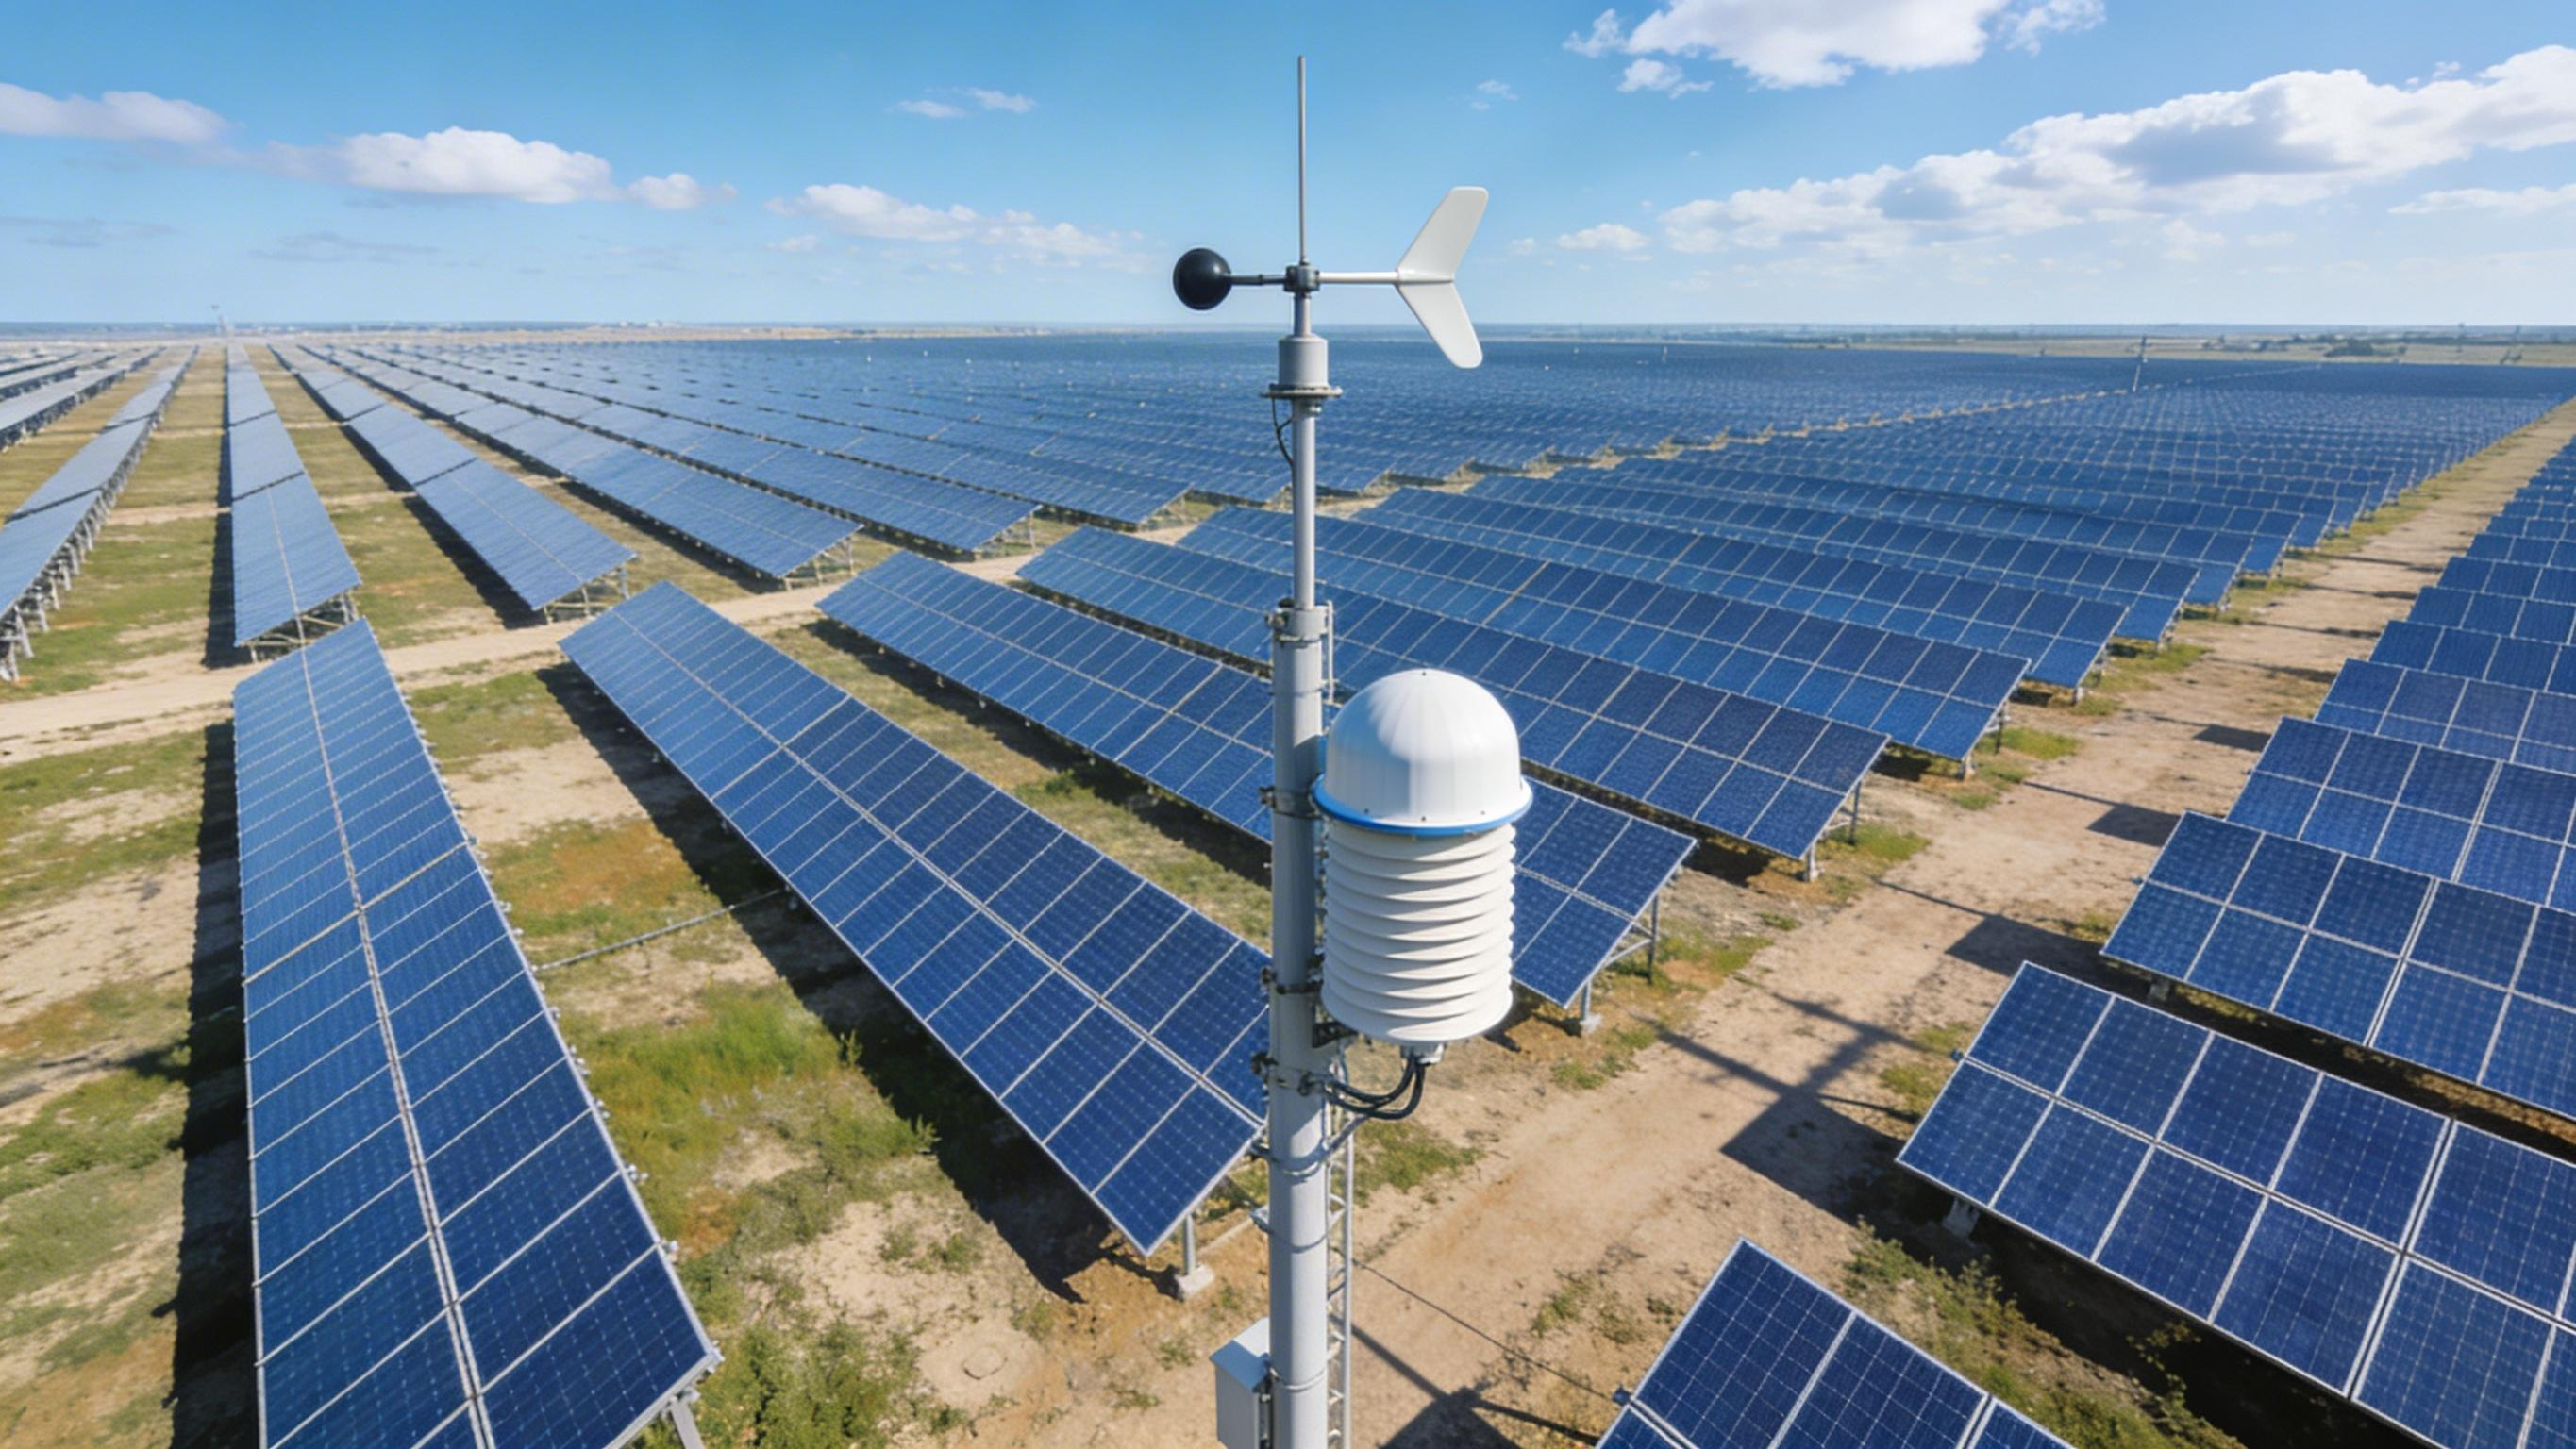

In [1]:
from PIL import Image as PILImage
from IPython.display import Image, display

img = PILImage.open("/content/solar image.jfif").convert("RGB")
img.save("/content/solar-image.png")

display(Image("/content/solar-image.png"))

In [ ]:

# Cell 1: Import libraries and configure the environment

import os
import glob
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Environment initialized successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Environment initialized successfully!
NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anikannal/solar-power-generation-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'solar-power-generation-data' dataset.
Path to dataset files: /kaggle/input/solar-power-generation-data


In [ ]:

import os
import glob

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file)


Number of CSV files: 4
/kaggle/input/solar-power-generation-data/Plant_2_Generation_Data.csv
/kaggle/input/solar-power-generation-data/Plant_2_Weather_Sensor_Data.csv
/kaggle/input/solar-power-generation-data/Plant_1_Weather_Sensor_Data.csv
/kaggle/input/solar-power-generation-data/Plant_1_Generation_Data.csv


In [ ]:

import pandas as pd

dataframes = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv", "")
    dataframes[name] = pd.read_csv(file)

    print(f"\nDataset: {name}")
    print("Rows and columns:", dataframes[name].shape)
    print("Column names:", dataframes[name].columns.tolist())



Dataset: Plant_2_Generation_Data
Rows and columns: (67698, 7)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

Dataset: Plant_2_Weather_Sensor_Data
Rows and columns: (3259, 6)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

Dataset: Plant_1_Weather_Sensor_Data
Rows and columns: (3182, 6)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

Dataset: Plant_1_Generation_Data
Rows and columns: (68778, 7)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']


In [ ]:

for name, df in dataframes.items():
    print(f"\n{'=' * 60}")
    print(name)
    display(df.head())



Plant_2_Generation_Data


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09
3,2020-05-15 00:00:00,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06
4,2020-05-15 00:00:00,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07



Plant_2_Weather_Sensor_Data


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
3,2020-05-15 00:45:00,4136001,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
4,2020-05-15 01:00:00,4136001,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0



Plant_1_Weather_Sensor_Data


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0



Plant_1_Generation_Data


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


# 🔍 Phase 1: Data Exploration and Analysis

## 📌 Step 1: Identify and Organize the Four Datasets

> **Goal:** Load, understand, and organize all four datasets for analysis.

| # | Dataset | Description |
|---|---------|-------------|
| 1️⃣ | Dataset 1 | *(add)* |
| 2️⃣ | Dataset 2 | *(add)* |
| 3️⃣ | Dataset 3 | *(add)* |
| 4️⃣ | Dataset 4 | *(add)* |

**Tasks:** 📥 Load  •  👀 Preview  •  📐 Check shape and types  •  🗃️ Name consistently

In [ ]:

# Identify the four datasets

for name, df in dataframes.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name}")
    print(f"{'='*60}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Data types:\n", df.dtypes)



DATASET: Plant_2_Generation_Data
Shape: (67698, 7)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']
Data types:
 DATE_TIME       object
PLANT_ID         int64
SOURCE_KEY      object
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

DATASET: Plant_2_Weather_Sensor_Data
Shape: (3259, 6)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
Data types:
 DATE_TIME               object
PLANT_ID                 int64
SOURCE_KEY              object
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object

DATASET: Plant_1_Weather_Sensor_Data
Shape: (3182, 6)
Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
Data types:
 DATE_TIME               object
PLANT_ID                 int64
SOURCE_KEY              object
AMBIENT_TE

## 🧹 Step 2: Check Missing Values and Duplicate Records

> **Goal:** Understand data quality before training our models.

| Check | What we look for |
|-------|------------------|
| ❓ **Missing values** | Empty cells in each column, per dataset |
| 📑 **Duplicate records** | Repeated rows or repeated timestamps |

**Tasks:** 🔎 Count missing values  •  📊 Calculate missing percentage  •  🗑️ Count duplicates  •  📝 Note issues for cleaning

In [ ]:

# Data quality assessment

quality_results = []

for name, df in dataframes.items():

    quality_results.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / (1024**2), 2
        )
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)


,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows,Memory (MB)
0,Plant_2_Generation_Data,67698,7,0,0,11.10
1,Plant_2_Weather_Sensor_Data,3259,6,0,0,0.51
2,Plant_1_Weather_Sensor_Data,3182,6,0,0,0.50
3,Plant_1_Generation_Data,68778,7,0,0,11.09


#Step 3. Convert date and time columns
Our solar dataset contains date and time information. We need to convert these columns into proper datetime objects.

In [ ]:

# Convert DATE_TIME columns to datetime

for name, df in dataframes.items():

    if "DATE_TIME" in df.columns:
        df["DATE_TIME"] = pd.to_datetime(
            df["DATE_TIME"],
            errors="coerce"
        )

        print(
            name,
            "| Date range:",
            df["DATE_TIME"].min(),
            "to",
            df["DATE_TIME"].max()
        )


Plant_2_Generation_Data | Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant_2_Weather_Sensor_Data | Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant_1_Weather_Sensor_Data | Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant_1_Generation_Data | Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00


##Step 4. Statistical analysis
Now calculate descriptive statistics for each dataset.

In [ ]:

# Statistical summary

for name, df in dataframes.items():

    print(f"\n{'='*60}")
    print("STATISTICAL SUMMARY:", name)
    print('='*60)

    display(df.describe().round(3))



STATISTICAL SUMMARY: Plant_2_Generation_Data


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,67698,67698.0,67698.000,67698.000,67698.000,6.769800e+04
mean,2020-06-01 10:44:33.650625024,4136001.0,246.702,241.278,3294.890,6.589448e+08
min,2020-05-15 00:00:00,4136001.0,0.000,0.000,0.000,0.000000e+00
25%,2020-05-23 21:00:00,4136001.0,0.000,0.000,272.750,1.996494e+07
50%,2020-06-01 23:00:00,4136001.0,0.000,0.000,2911.000,2.826276e+08
75%,2020-06-09 23:30:00,4136001.0,446.592,438.215,5534.000,1.348495e+09
max,2020-06-17 23:45:00,4136001.0,1420.933,1385.420,9873.000,2.247916e+09
std,NaN,0.0,370.570,362.112,2919.448,7.296678e+08



STATISTICAL SUMMARY: Plant_2_Weather_Sensor_Data


,DATE_TIME,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3259,3259.0,3259.000,3259.000,3259.000
mean,2020-06-01 00:04:35.053697536,4136001.0,28.069,32.772,0.233
min,2020-05-15 00:00:00,4136001.0,20.942,20.265,0.000
25%,2020-05-23 12:07:30,4136001.0,24.602,23.717,0.000
50%,2020-06-01 00:00:00,4136001.0,26.981,27.535,0.019
75%,2020-06-09 12:07:30,4136001.0,31.057,40.481,0.439
max,2020-06-17 23:45:00,4136001.0,39.182,66.636,1.099
std,NaN,0.0,4.062,11.344,0.313



STATISTICAL SUMMARY: Plant_1_Weather_Sensor_Data


,DATE_TIME,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3182,3182.0,3182.000,3182.000,3182.000
mean,2020-06-01 05:52:22.080452608,4135001.0,25.532,31.091,0.228
min,2020-05-15 00:00:00,4135001.0,20.399,18.140,0.000
25%,2020-05-23 22:48:45,4135001.0,22.705,21.091,0.000
50%,2020-06-01 09:52:30,4135001.0,24.614,24.618,0.025
75%,2020-06-09 16:56:15,4135001.0,27.921,41.308,0.450
max,2020-06-17 23:45:00,4135001.0,35.252,65.546,1.222
std,NaN,0.0,3.355,12.261,0.301



STATISTICAL SUMMARY: Plant_1_Generation_Data


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,68778,68778.0,68778.000,68778.000,68778.000,68778.000
mean,2020-06-01 08:02:49.458256896,4135001.0,3147.426,307.803,3295.969,6978711.761
min,2020-05-15 00:00:00,4135001.0,0.000,0.000,0.000,6183645.000
25%,2020-05-24 00:45:00,4135001.0,0.000,0.000,0.000,6512002.536
50%,2020-06-01 14:30:00,4135001.0,429.000,41.494,2658.714,7146685.000
75%,2020-06-09 20:00:00,4135001.0,6366.964,623.619,6274.000,7268705.906
max,2020-06-17 23:45:00,4135001.0,14471.125,1410.950,9163.000,7846821.000
std,NaN,0.0,4036.457,394.396,3145.178,416271.983


##Step 5. Visualize solar power generation
This is our first major visualization.

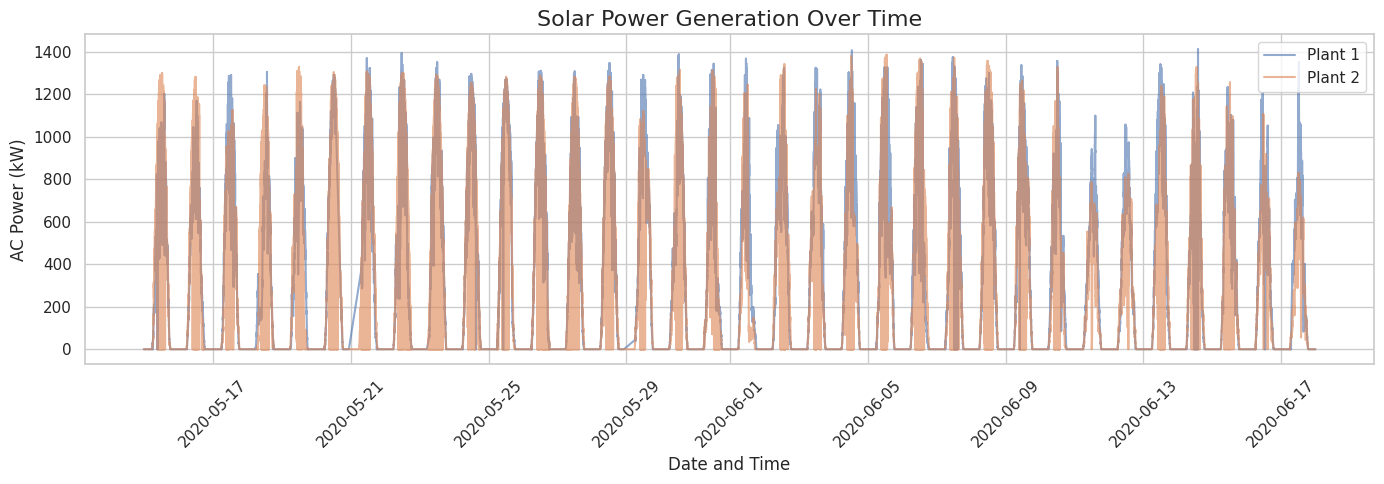

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plant1_gen = dataframes["Plant_1_Generation_Data"]
plant2_gen = dataframes["Plant_2_Generation_Data"]

plt.figure(figsize=(14, 5))

plt.plot(
    plant1_gen["DATE_TIME"],
    plant1_gen["AC_POWER"],
    alpha=0.6,
    label="Plant 1"
)

plt.plot(
    plant2_gen["DATE_TIME"],
    plant2_gen["AC_POWER"],
    alpha=0.6,
    label="Plant 2"
)

plt.title("Solar Power Generation Over Time", fontsize=16)
plt.xlabel("Date and Time")
plt.ylabel("AC Power (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## ☀️ Step 6: Analyze the Relationship Between Irradiation and Power Generation

> **Goal:** Solar irradiation is one of the most important variables affecting photovoltaic power production. Here we measure how strongly it drives power output.

| Analysis | What we look for |
|----------|------------------|
| 📈 **Scatter plot** | Irradiation vs. DC/AC power pattern |
| 🔗 **Correlation** | Strength of the relationship |
| 🚨 **Outliers** | Points where power is low despite high irradiation (possible faults) |

**Tasks:** 📊 Plot irradiation vs. power  •  🔢 Calculate correlation  •  🔍 Note unusual patterns

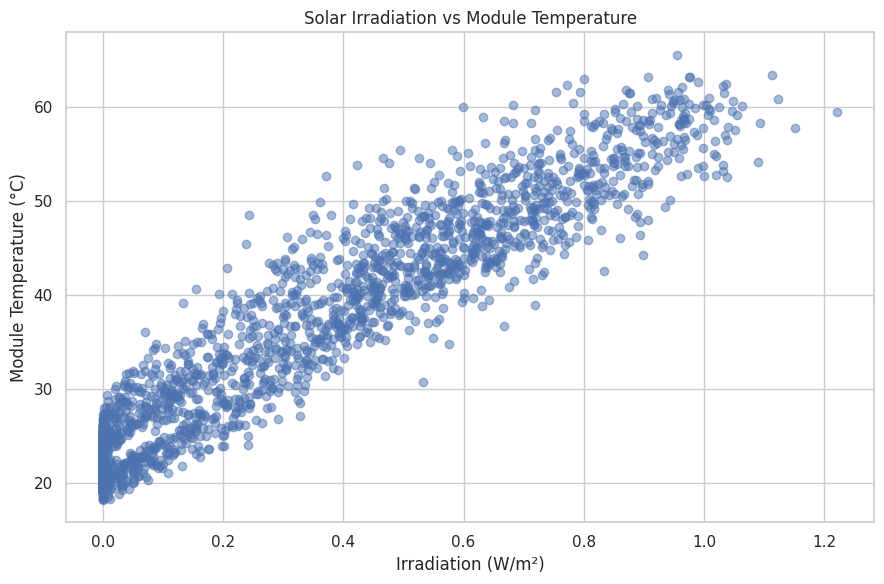

In [ ]:

plant1_weather = dataframes["Plant_1_Weather_Sensor_Data"]

plt.figure(figsize=(9, 6))

plt.scatter(
    plant1_weather["IRRADIATION"],
    plant1_weather["MODULE_TEMPERATURE"],
    alpha=0.5
)

plt.title("Solar Irradiation vs Module Temperature")
plt.xlabel("Irradiation (W/m²)")
plt.ylabel("Module Temperature (°C)")
plt.tight_layout()
plt.show()


##Step 7. Analyze timestamps and inverter measurements

In [ ]:

# Timestamp and inverter analysis

for name, df in dataframes.items():

    print("\n", "=" * 60)
    print(name)

    print("First timestamp:", df["DATE_TIME"].min())
    print("Last timestamp:", df["DATE_TIME"].max())

    print("Unique timestamps:", df["DATE_TIME"].nunique())

    if "SOURCE_KEY" in df.columns:
        print("Number of inverters/sensors:",
              df["SOURCE_KEY"].nunique())

    print("Average records per timestamp:",
          round(len(df) / df["DATE_TIME"].nunique(), 2))



Plant_2_Generation_Data
First timestamp: 2020-05-15 00:00:00
Last timestamp: 2020-06-17 23:45:00
Unique timestamps: 3259
Number of inverters/sensors: 22
Average records per timestamp: 20.77

Plant_2_Weather_Sensor_Data
First timestamp: 2020-05-15 00:00:00
Last timestamp: 2020-06-17 23:45:00
Unique timestamps: 3259
Number of inverters/sensors: 1
Average records per timestamp: 1.0

Plant_1_Weather_Sensor_Data
First timestamp: 2020-05-15 00:00:00
Last timestamp: 2020-06-17 23:45:00
Unique timestamps: 3182
Number of inverters/sensors: 1
Average records per timestamp: 1.0

Plant_1_Generation_Data
First timestamp: 2020-05-15 00:00:00
Last timestamp: 2020-06-17 23:45:00
Unique timestamps: 3158
Number of inverters/sensors: 22
Average records per timestamp: 21.78


##Step 8. Aggregate generation data by timestamp
Each plant has multiple inverters. We will calculate total plant generation at each timestamp by summing their AC and DC power.

In [ ]:

# Separate generation datasets

plant1_gen = dataframes["Plant_1_Generation_Data"].copy()
plant2_gen = dataframes["Plant_2_Generation_Data"].copy()

# Aggregate inverter measurements into plant-level measurements

plant1_agg = (
    plant1_gen.groupby("DATE_TIME")
    .agg({
        "DC_POWER": "sum",
        "AC_POWER": "sum",
        "DAILY_YIELD": "sum",
        "TOTAL_YIELD": "sum"
    })
    .reset_index()
)

plant2_agg = (
    plant2_gen.groupby("DATE_TIME")
    .agg({
        "DC_POWER": "sum",
        "AC_POWER": "sum",
        "DAILY_YIELD": "sum",
        "TOTAL_YIELD": "sum"
    })
    .reset_index()
)

print("Plant 1 aggregated shape:", plant1_agg.shape)
print("Plant 2 aggregated shape:", plant2_agg.shape)

display(plant1_agg.head())
display(plant2_agg.head())


Plant 1 aggregated shape: (3158, 5)
Plant 2 aggregated shape: (3259, 5)


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,0.0,0.0,0.0,143581676.0
1,2020-05-15 00:15:00,0.0,0.0,0.0,143581676.0
2,2020-05-15 00:30:00,0.0,0.0,0.0,143581676.0
3,2020-05-15 00:45:00,0.0,0.0,0.0,143581676.0
4,2020-05-15 01:00:00,0.0,0.0,0.0,150761642.0


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,0.0,0.0,48899.938095,1.418960e+10
1,2020-05-15 00:15:00,0.0,0.0,28401.000000,1.418960e+10
2,2020-05-15 00:30:00,0.0,0.0,28401.000000,1.418960e+10
3,2020-05-15 00:45:00,0.0,0.0,28401.000000,1.418960e+10
4,2020-05-15 01:00:00,0.0,0.0,26516.000000,1.418960e+10


##Step 9. Prepare weather datasets

In [ ]:

# Separate weather datasets

plant1_weather = dataframes["Plant_1_Weather_Sensor_Data"].copy()
plant2_weather = dataframes["Plant_2_Weather_Sensor_Data"].copy()

# Inspect weather measurements

print("Plant 1 weather:")
display(plant1_weather.head())

print("Plant 2 weather:")
display(plant2_weather.head())


Plant 1 weather:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


Plant 2 weather:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
3,2020-05-15 00:45:00,4136001,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
4,2020-05-15 01:00:00,4136001,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0


##Step 10. Merge generation and weather data
We will merge each plant's aggregated generation with its corresponding weather measurements.

In [ ]:

# Merge generation and weather data using timestamps

plant1_data = pd.merge(
    plant1_agg,
    plant1_weather,
    on="DATE_TIME",
    how="inner"
)

plant2_data = pd.merge(
    plant2_agg,
    plant2_weather,
    on="DATE_TIME",
    how="inner"
)

# Add plant identification

plant1_data["PLANT"] = "Plant 1"
plant2_data["PLANT"] = "Plant 2"

# Combine both plants

solar_data = pd.concat(
    [plant1_data, plant2_data],
    ignore_index=True
)

print("Plant 1 merged shape:", plant1_data.shape)
print("Plant 2 merged shape:", plant2_data.shape)
print("Combined dataset shape:", solar_data.shape)

display(solar_data.head())


Plant 1 merged shape: (3157, 11)
Plant 2 merged shape: (3259, 11)
Combined dataset shape: (6416, 11)


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT
0,2020-05-15 00:00:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,Plant 1
1,2020-05-15 00:15:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,Plant 1
2,2020-05-15 00:30:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,Plant 1
3,2020-05-15 00:45:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0,Plant 1
4,2020-05-15 01:00:00,0.0,0.0,0.0,150761642.0,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0,Plant 1


In [ ]:

# Check the final combined dataset

print("Missing values:")
display(solar_data.isnull().sum())

print("\nPlant distribution:")
display(solar_data["PLANT"].value_counts())

print("\nStatistical summary:")
display(solar_data.describe().round(3))

print("\nDate range:")
print(solar_data["DATE_TIME"].min())
print(solar_data["DATE_TIME"].max())


Missing values:


,0
DATE_TIME,0
DC_POWER,0
AC_POWER,0
DAILY_YIELD,0
TOTAL_YIELD,0
PLANT_ID,0
SOURCE_KEY,0
AMBIENT_TEMPERATURE,0
MODULE_TEMPERATURE,0
IRRADIATION,0



Plant distribution:


,count
PLANT,
Plant 2,3259
Plant 1,3157



Statistical summary:


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,6416,6416.000,6416.000,6416.000,6.416000e+03,6416.000,6416.000,6416.000,6416.000
mean,2020-06-01 03:19:58.784289536,36338.094,5844.946,70094.329,7.027618e+09,4135508.949,26.835,31.987,0.231
min,2020-05-15 00:00:00,0.000,0.000,0.000,0.000000e+00,4135001.000,20.399,18.140,0.000
25%,2020-05-23 17:30:00,0.000,0.000,10598.237,1.536211e+08,4135001.000,23.673,22.467,0.000
50%,2020-06-01 06:15:00,1264.466,638.474,71595.000,9.777357e+09,4136001.000,25.974,26.478,0.024
75%,2020-06-09 15:03:45,17784.793,11898.457,120673.000,1.419024e+10,4136001.000,29.367,40.932,0.446
max,2020-06-17 23:45:00,298937.786,29150.212,193770.000,1.419408e+10,4136001.000,39.182,66.636,1.222
std,NaN,69582.971,7576.958,57787.310,6.825671e+09,499.976,3.934,11.836,0.307



Date range:
2020-05-15 00:00:00
2020-06-17 23:45:00


##Step 12. Visualize total solar power generation
Now we can plot the actual aggregated power generation instead of individual inverter measurements.

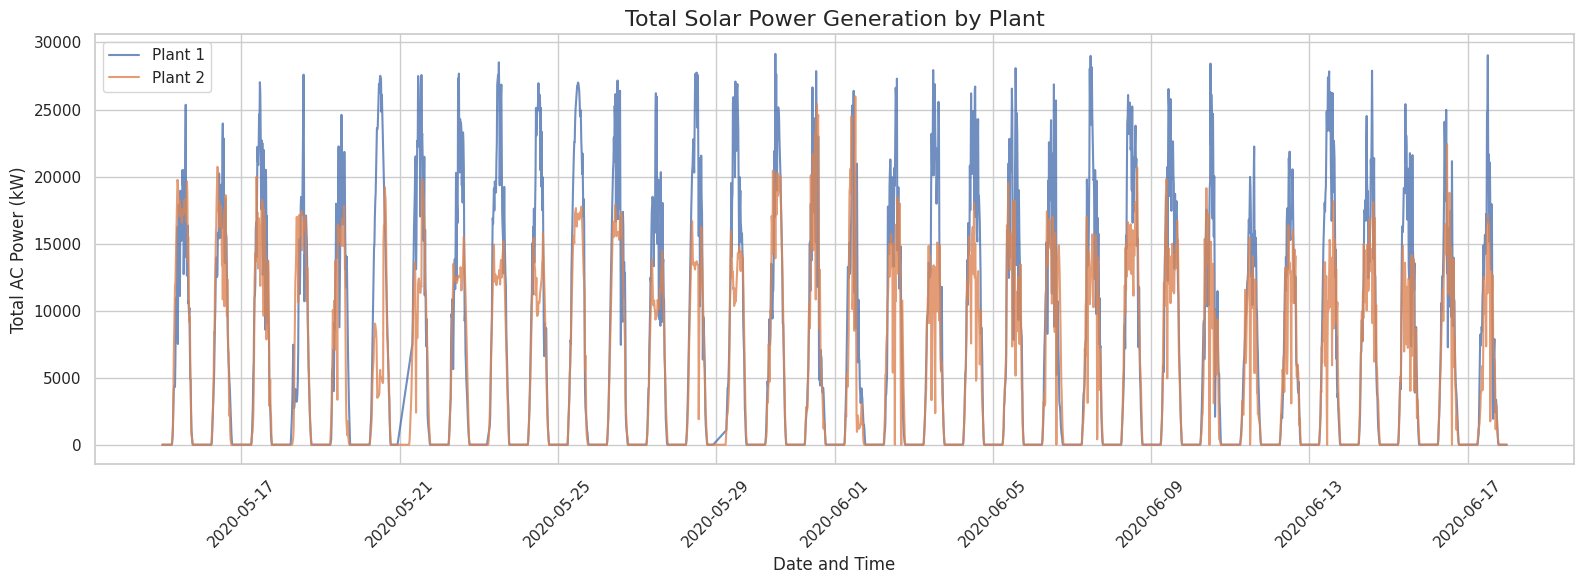

In [ ]:

# Total AC power generation over time

plt.figure(figsize=(16, 6))

for plant, df in solar_data.groupby("PLANT"):

    df = df.sort_values("DATE_TIME")

    plt.plot(
        df["DATE_TIME"],
        df["AC_POWER"],
        label=plant,
        alpha=0.8
    )

plt.title("Total Solar Power Generation by Plant",
          fontsize=16)

plt.xlabel("Date and Time")
plt.ylabel("Total AC Power (kW)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##2. Phase 2.1 — Verify timestamp consistency
Before training, let's check whether the observations are correctly aligned and whether there are missing time intervals.

In [ ]:

# Timestamp consistency analysis

for plant, df in solar_data.groupby("PLANT"):

    df = df.sort_values("DATE_TIME").copy()

    time_diff = df["DATE_TIME"].diff()

    print("\n", "=" * 50)
    print(plant)
    print("=" * 50)

    print("Total observations:", len(df))
    print("Unique timestamps:", df["DATE_TIME"].nunique())
    print("Duplicate timestamps:", df["DATE_TIME"].duplicated().sum())

    print("\nTime interval distribution:")
    print(time_diff.value_counts().head(10))

    print("\nMissing 15-minute intervals:",
          (time_diff > pd.Timedelta(minutes=15)).sum())



Plant 1
Total observations: 3157
Unique timestamps: 3157
Duplicate timestamps: 0

Time interval distribution:
DATE_TIME
0 days 00:15:00    3146
0 days 00:30:00       3
0 days 03:00:00       1
0 days 04:15:00       1
0 days 01:00:00       1
0 days 09:00:00       1
0 days 01:45:00       1
0 days 08:00:00       1
0 days 00:45:00       1
Name: count, dtype: int64

Missing 15-minute intervals: 10

Plant 2
Total observations: 3259
Unique timestamps: 3259
Duplicate timestamps: 0

Time interval distribution:
DATE_TIME
0 days 00:15:00    3253
0 days 00:30:00       5
Name: count, dtype: int64

Missing 15-minute intervals: 5


##3. Phase 2.2 — Explore correlations
We want to understand which variables are associated with solar power generation.

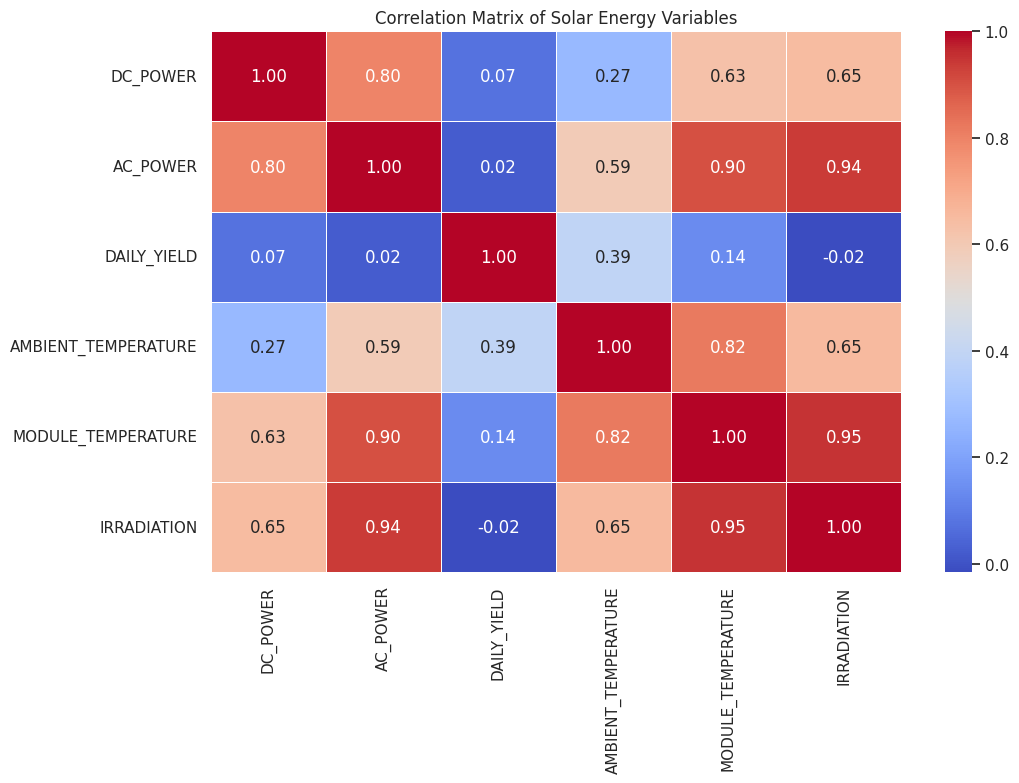

In [ ]:

# Correlation analysis

correlation_columns = [
    "DC_POWER",
    "AC_POWER",
    "DAILY_YIELD",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

correlation_matrix = solar_data[correlation_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Solar Energy Variables")
plt.tight_layout()
plt.show()


##4. Phase 2.3 — Analyze solar generation distributions
Let's examine how power generation varies across the two plants.

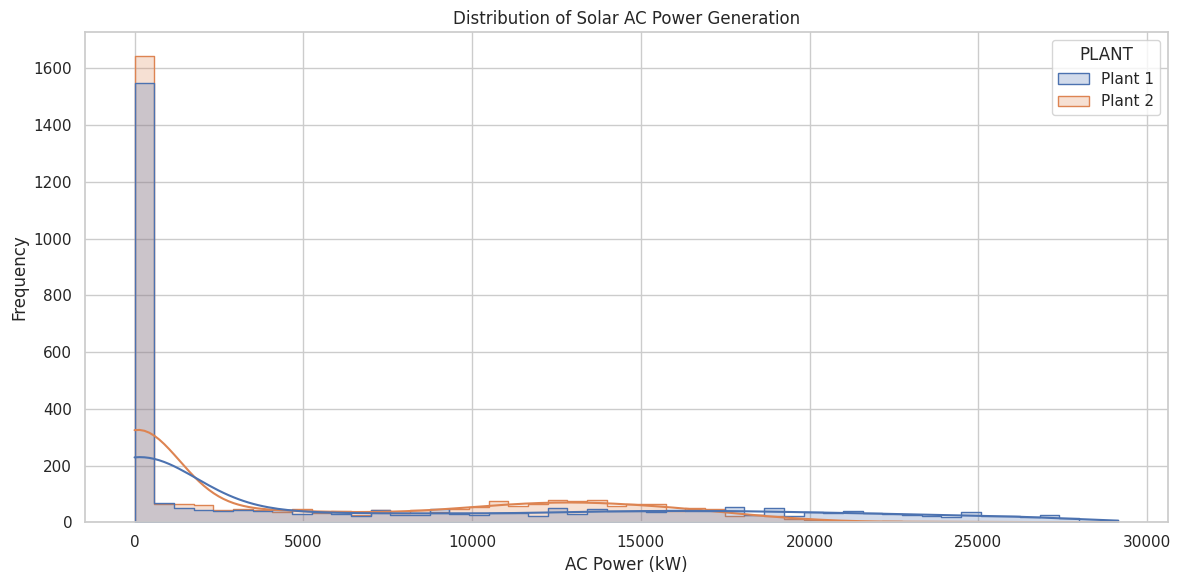

In [ ]:

# Distribution of AC power

plt.figure(figsize=(12, 6))

sns.histplot(
    data=solar_data,
    x="AC_POWER",
    hue="PLANT",
    kde=True,
    bins=50,
    element="step"
)

plt.title("Distribution of Solar AC Power Generation")
plt.xlabel("AC Power (kW)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


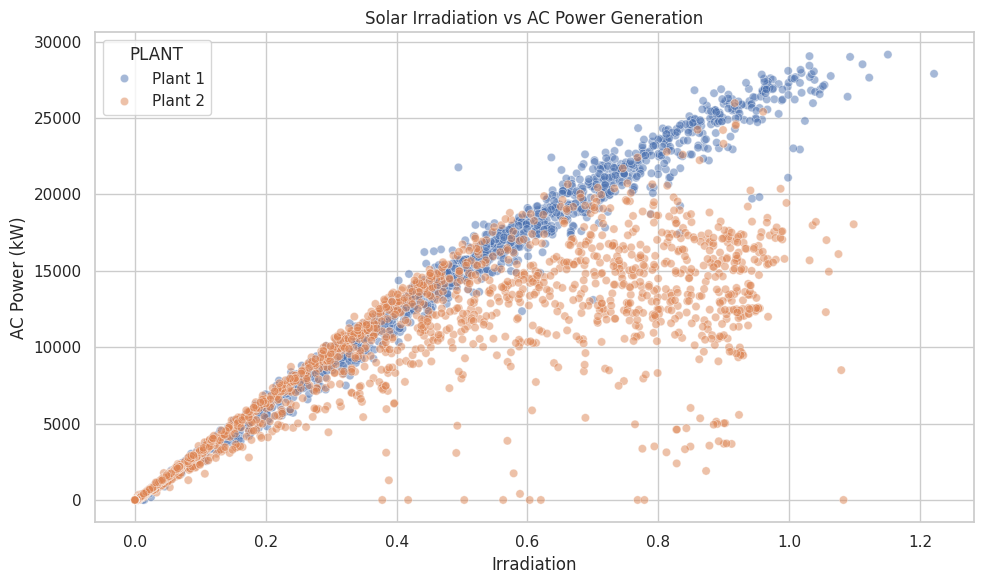

In [ ]:

# Irradiation versus AC power

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=solar_data,
    x="IRRADIATION",
    y="AC_POWER",
    hue="PLANT",
    alpha=0.5
)

plt.title("Solar Irradiation vs AC Power Generation")
plt.xlabel("Irradiation")
plt.ylabel("AC Power (kW)")

plt.tight_layout()
plt.show()


##Phase 3 — Feature engineering for AI
Now we prepare the variables that our machine learning models will learn from.

##AC_POWER
Predict the next 15-minute solar power output using information available at the current timestamp.

This is a genuine forecasting task rather than simply predicting power at the same time as the weather measurement

##Step 1. Create time-based features
Solar power generation follows daily and seasonal patterns. We can extract useful information from timestamps.

In [ ]:

# Create a working copy

model_data = solar_data.copy()

# Extract time features
model_data["HOUR"] = model_data["DATE_TIME"].dt.hour
model_data["MINUTE"] = model_data["DATE_TIME"].dt.minute
model_data["DAY_OF_WEEK"] = model_data["DATE_TIME"].dt.dayofweek
model_data["DAY_OF_YEAR"] = model_data["DATE_TIME"].dt.dayofyear

# Cyclical encoding of time
model_data["HOUR_SIN"] = np.sin(
    2 * np.pi * model_data["HOUR"] / 24
)

model_data["HOUR_COS"] = np.cos(
    2 * np.pi * model_data["HOUR"] / 24
)

model_data["MINUTE_OF_DAY"] = (
    model_data["HOUR"] * 60 + model_data["MINUTE"]
)

model_data["TIME_SIN"] = np.sin(
    2 * np.pi * model_data["MINUTE_OF_DAY"] / 1440
)

model_data["TIME_COS"] = np.cos(
    2 * np.pi * model_data["MINUTE_OF_DAY"] / 1440
)

display(model_data.head())


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT,HOUR,MINUTE,DAY_OF_WEEK,DAY_OF_YEAR,HOUR_SIN,HOUR_COS,MINUTE_OF_DAY,TIME_SIN,TIME_COS
0,2020-05-15 00:00:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,Plant 1,0,0,4,136,0.000000,1.000000,0,0.000000,1.000000
1,2020-05-15 00:15:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,Plant 1,0,15,4,136,0.000000,1.000000,15,0.065403,0.997859
2,2020-05-15 00:30:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,Plant 1,0,30,4,136,0.000000,1.000000,30,0.130526,0.991445
3,2020-05-15 00:45:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0,Plant 1,0,45,4,136,0.000000,1.000000,45,0.195090,0.980785
4,2020-05-15 01:00:00,0.0,0.0,0.0,150761642.0,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0,Plant 1,1,0,4,136,0.258819,0.965926,60,0.258819,0.965926


##Step 2. Create the forecasting target
We will predict AC power 15 minutes into the future.

We will only retain consecutive observations separated by exactly 15 minutes.

In [ ]:

# Sort observations within each plant

model_data = model_data.sort_values(
    ["PLANT", "DATE_TIME"]
).copy()

# Next observation's AC power
model_data["TARGET_AC_POWER"] = (
    model_data.groupby("PLANT")["AC_POWER"].shift(-1)
)

# Next observation's timestamp
model_data["NEXT_TIMESTAMP"] = (
    model_data.groupby("PLANT")["DATE_TIME"].shift(-1)
)

# Verify the next observation is exactly 15 minutes later
valid_interval = (
    model_data["NEXT_TIMESTAMP"] -
    model_data["DATE_TIME"]
) == pd.Timedelta(minutes=15)

# Keep only valid forecasting pairs
model_data = model_data[valid_interval].copy()

model_data.drop(
    columns=["NEXT_TIMESTAMP"],
    inplace=True
)

print("Forecasting dataset shape:", model_data.shape)
display(
    model_data[
        ["PLANT", "DATE_TIME", "AC_POWER", "TARGET_AC_POWER"]
    ].head(10)
)


Forecasting dataset shape: (6399, 21)


,PLANT,DATE_TIME,AC_POWER,TARGET_AC_POWER
0,Plant 1,2020-05-15 00:00:00,0.0,0.0
1,Plant 1,2020-05-15 00:15:00,0.0,0.0
2,Plant 1,2020-05-15 00:30:00,0.0,0.0
3,Plant 1,2020-05-15 00:45:00,0.0,0.0
4,Plant 1,2020-05-15 01:00:00,0.0,0.0
5,Plant 1,2020-05-15 01:15:00,0.0,0.0
6,Plant 1,2020-05-15 01:30:00,0.0,0.0
7,Plant 1,2020-05-15 01:45:00,0.0,0.0
8,Plant 1,2020-05-15 02:00:00,0.0,0.0
9,Plant 1,2020-05-15 02:15:00,0.0,0.0


##Step 3. Select input features
We will exclude DAILY_YIELD and TOTAL_YIELD initially because they are cumulative or running measurements and can introduce misleading information into the forecasting model.

We will also exclude PLANT_ID because it is an identifier, not a physical measurement.

In [ ]:

# Select model input features

features = [
    "DC_POWER",
    "AC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION",
    "HOUR_SIN",
    "HOUR_COS",
    "TIME_SIN",
    "TIME_COS"
]

# Encode plant identity
model_data["PLANT_2"] = (
    model_data["PLANT"] == "Plant 2"
).astype(int)

features.append("PLANT_2")

target = "TARGET_AC_POWER"

# Remove incomplete records if any
model_data = model_data.dropna(
    subset=features + [target]
).copy()

X = model_data[features]
y = model_data[target]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(features)

print("\nTarget variable:", target)


Input feature shape: (6399, 10)
Target shape: (6399,)

Input features:
['DC_POWER', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR_SIN', 'HOUR_COS', 'TIME_SIN', 'TIME_COS', 'PLANT_2']

Target variable: TARGET_AC_POWER


##Step 4. Split training and testing data chronologically
For time-series forecasting, we should not randomly shuffle the observations. We train on earlier dates and test on later dates.

In [ ]:

# Chronological 80/20 train-test split

split_date = model_data["DATE_TIME"].quantile(0.80)

train_mask = model_data["DATE_TIME"] < split_date
test_mask = ~train_mask

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training period:")
print(model_data.loc[train_mask, "DATE_TIME"].min())
print("to")
print(model_data.loc[train_mask, "DATE_TIME"].max())

print("\nTesting period:")
print(model_data.loc[test_mask, "DATE_TIME"].min())
print("to")
print(model_data.loc[test_mask, "DATE_TIME"].max())

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training period:
2020-05-15 00:00:00
to
2020-06-11 07:00:00

Testing period:
2020-06-11 07:15:00
to
2020-06-17 23:30:00

Training samples: 5118
Testing samples: 1281


##Phase 4.2 — Train the Linear Regression model
Linear Regression will be our baseline model. It learns the relationship between the current power, weather conditions, time features, and the AC power expected 15 minutes later.

We'll use a pipeline with StandardScaler to standardize the features before training. The scaler is fitted only on the training data to avoid data leakage.

In [ ]:
# Import required libraries

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

# 1. Create the Linear Regression pipeline

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# 2. Train the model

linear_model.fit(X_train, y_train)

# 3. Make predictions on testing data

y_pred_lr = linear_model.predict(X_test)

# 4. Evaluate model performance

mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

# 5. Display results

print("LINEAR REGRESSION MODEL RESULTS")
print("=" * 45)

print(f"MAE:  {mae_lr:.4f}")
print(f"RMSE: {rmse_lr:.4f}")
print(f"R²:   {r2_lr:.4f}")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

LINEAR REGRESSION MODEL RESULTS
MAE:  1285.7108
RMSE: 2126.6981
R²:   0.9046

Training samples: 5118
Testing samples: 1281


##Phase 4.3 — Random Forest Regression
Random Forest combines multiple decision trees. It can learn nonlinear relationships between solar irradiation, temperature, current power, and future power.

Unlike Linear Regression, Random Forest does not require feature scaling.

In [ ]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

# 1. Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate performance
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

# 5. Display results
print("RANDOM FOREST REGRESSION RESULTS")
print("=" * 45)

print(f"MAE:  {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²:   {r2_rf:.4f}")

RANDOM FOREST REGRESSION RESULTS
MAE:  1090.1045
RMSE: 2149.5362
R²:   0.9026


##Phase 4.4 — XGBoost Regression
Next, we'll train XGBoost. It uses gradient boosting, building decision trees sequentially so that each new tree attempts to correct errors made by the previous trees.

In [ ]:
# Install XGBoost if it is not already installed
!pip install -q xgboost

# Import XGBoost
from xgboost import XGBRegressor

# 1. Create the XGBoost model
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
xgb_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# 4. Evaluate performance
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

r2_xgb = r2_score(y_test, y_pred_xgb)

# 5. Display results
print("XGBOOST REGRESSION RESULTS")
print("=" * 45)

print(f"MAE:  {mae_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"R²:   {r2_xgb:.4f}")

XGBOOST REGRESSION RESULTS
MAE:  1107.2938
RMSE: 2211.4083
R²:   0.8969


##Phase 4.5 — Visualize model performance
Let's create three professional plots:
1. Actual versus predicted AC power.
2. Prediction errors (residuals).
3. Comparison of the three models.

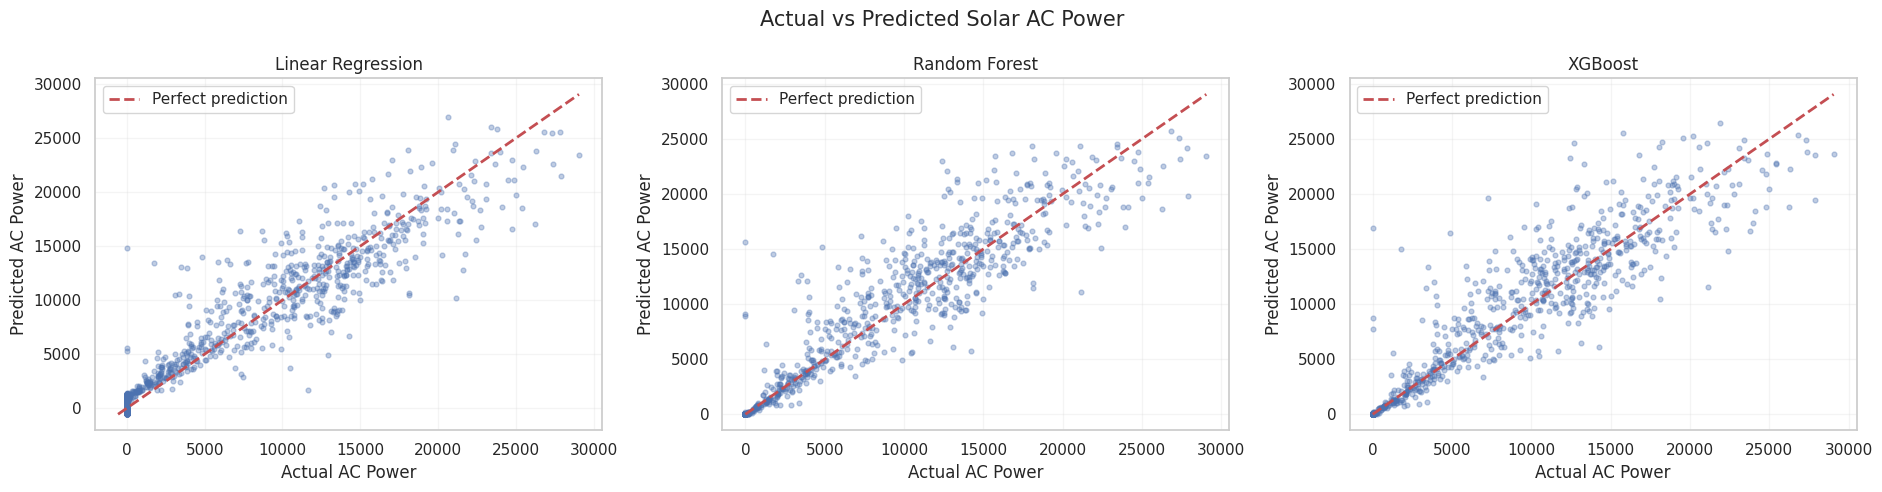

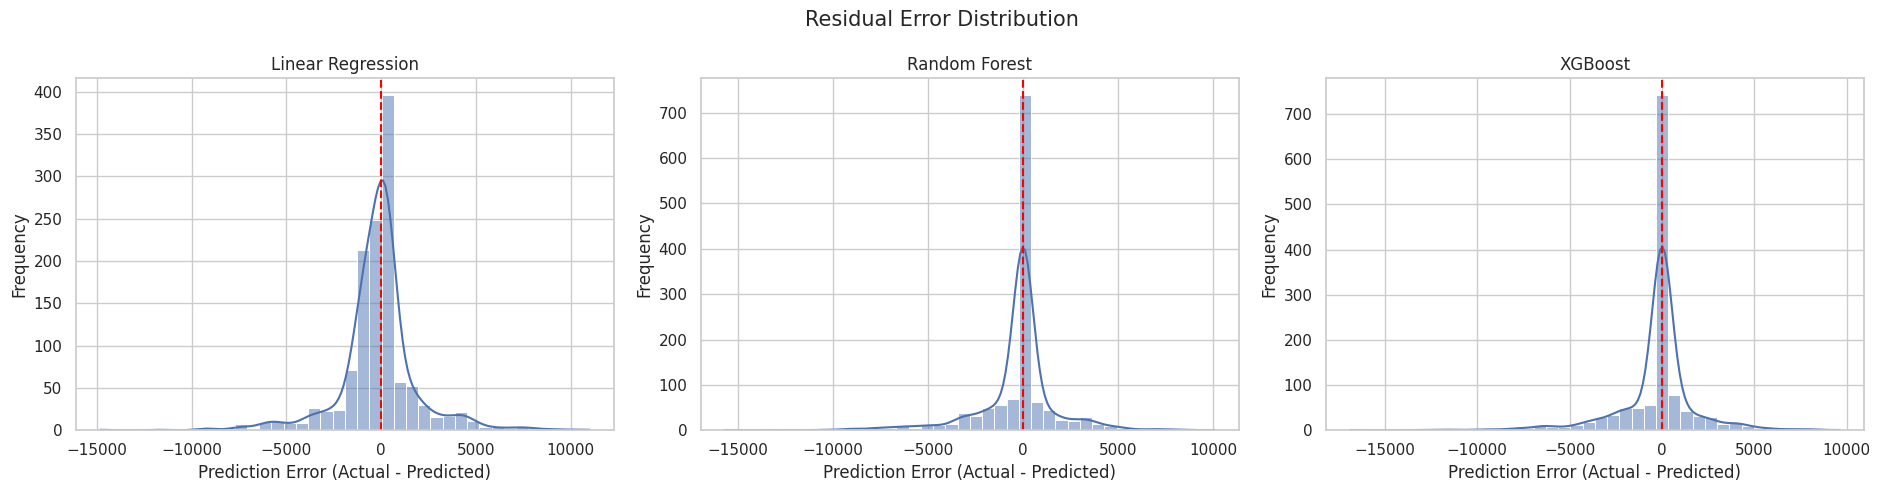

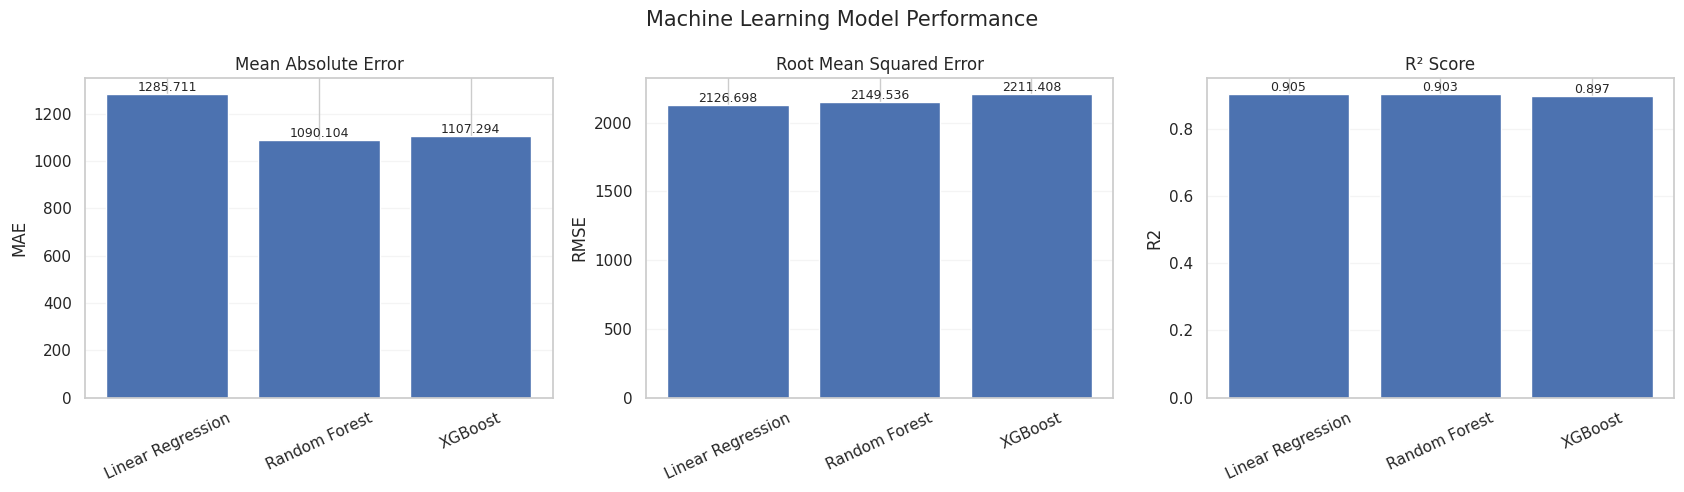

MODEL PERFORMANCE SUMMARY


,Model,MAE,RMSE,R2
0,Linear Regression,1285.7108,2126.6981,0.9046
1,Random Forest,1090.1045,2149.5362,0.9026
2,XGBoost,1107.2938,2211.4083,0.8969


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Store predictions for comparison
predictions = {
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

# ------------------------------------------------
# PLOT 1: Actual vs Predicted AC Power
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    ax.scatter(y_test, pred, alpha=0.35, s=12)

    # Ideal prediction line
    minimum = min(y_test.min(), pred.min())
    maximum = max(y_test.max(), pred.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--",
        linewidth=2,
        label="Perfect prediction"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual AC Power")
    ax.set_ylabel("Predicted AC Power")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Actual vs Predicted Solar AC Power", fontsize=15)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 2: Residual Error Distribution
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test.values - pred

    sns.histplot(
        residuals,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Prediction Error (Actual - Predicted)")
    ax.set_ylabel("Frequency")

plt.suptitle("Residual Error Distribution", fontsize=15)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 3: Model Performance Comparison
# ------------------------------------------------

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [mae_lr, mae_rf, mae_xgb],
    "RMSE": [rmse_lr, rmse_rf, rmse_xgb],
    "R2": [r2_lr, r2_rf, r2_xgb]
})

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE", "RMSE", "R2"]
titles = ["Mean Absolute Error", "Root Mean Squared Error", "R² Score"]

for ax, metric, title in zip(axes, metrics, titles):

    bars = ax.bar(results["Model"], results[metric])

    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.2)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.suptitle("Machine Learning Model Performance", fontsize=15)
plt.tight_layout()
plt.show()

print("MODEL PERFORMANCE SUMMARY")
display(results.round(4))

##Phase 5.1 — Prepare sequential data
We will use the previous four 15-minute observations (one hour of history) to predict AC power 15 minutes after the final observation.

This means:
- Input: Four consecutive observations.
- Forecast horizon: 15 minutes ahead.
- Sequence length: 4 time steps.
- Training/testing split: Preserve your existing chronological split.

In [ ]:
# Import libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 1. Define sequence length
sequence_length = 4

# 2. Fit scalers using training data only
X_scaler = StandardScaler()
y_scaler = MinMaxScaler()

X_scaler.fit(model_data.loc[train_mask, features])
y_scaler.fit(model_data.loc[train_mask, [target]])

# 3. Scale features and target
scaled_X = X_scaler.transform(model_data[features])
scaled_y = y_scaler.transform(model_data[[target]]).ravel()

# 4. Generate sequences separately for each plant
X_sequences = []
y_sequences = []
sequence_dates = []

for plant, group in model_data.groupby("PLANT", sort=False):

    indices = group.sort_values("DATE_TIME").index.tolist()

    for i in range(sequence_length - 1, len(indices)):

        window_indices = indices[i - sequence_length + 1:i + 1]

        window_dates = model_data.loc[
            window_indices, "DATE_TIME"
        ]

        # Ensure all four observations are consecutive
        if not (window_dates.diff().dropna() ==
                pd.Timedelta(minutes=15)).all():
            continue

        X_sequences.append(scaled_X[
            model_data.index.get_indexer(window_indices)
        ])

        y_sequences.append(scaled_y[
            model_data.index.get_loc(indices[i])
        ])

        sequence_dates.append(
            model_data.loc[indices[i], "DATE_TIME"]
        )

# Convert to NumPy arrays
X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)
sequence_dates = pd.to_datetime(sequence_dates)

# 5. Chronological train/test split
lstm_train_mask = sequence_dates < split_date
lstm_test_mask = sequence_dates >= split_date

X_train_lstm = X_sequences[lstm_train_mask]
X_test_lstm = X_sequences[lstm_test_mask]

y_train_lstm = y_sequences[lstm_train_mask]
y_test_lstm = y_sequences[lstm_test_mask]

print("LSTM DATA PREPARATION")
print("=" * 45)

print("Sequence length:", sequence_length)
print("Training sequences:", len(X_train_lstm))
print("Testing sequences:", len(X_test_lstm))

print("Training input shape:", X_train_lstm.shape)
print("Testing input shape:", X_test_lstm.shape)

LSTM DATA PREPARATION
Sequence length: 4
Training sequences: 5070
Testing sequences: 1278
Training input shape: (5070, 4, 10)
Testing input shape: (1278, 4, 10)


##Phase 5.2 — Build the LSTM model
We'll use:
- An LSTM layer with 64 units to learn temporal patterns.
- Dropout to help reduce overfitting.
- A second LSTM layer with 32 units.
- A Dense output layer to predict the next AC power value.

In [ ]:
# 1. Build the LSTM architecture

lstm_model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(sequence_length, len(features))
    ),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1)
])

# 2. Compile the model

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# 3. Display model architecture

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4, 64)          │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train the model
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=50,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0215 - mae: 0.0902 - val_loss: 0.0079 - val_mae: 0.0578
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0100 - mae: 0.0627 - val_loss: 0.0074 - val_mae: 0.0481
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0078 - mae: 0.0537 - val_loss: 0.0082 - val_mae: 0.0517
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0076 - mae: 0.0524 - val_loss: 0.0075 - val_mae: 0.0484
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0074 - mae: 0.0503 - val_loss: 0.0070 - val_mae: 0.0441
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0070 - mae: 0.0490 - val_loss: 0.0068 - val_mae: 0.0432
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0068 - mae: 0.0478 - val_loss: 0.0061 - val_mae: 0.0398
Epoch 8/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0060 - mae: 0.0448 - val_loss: 0.0061 - val_mae: 0.0395
Epoch 9/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0063 - m

##Phase 5.4 — Evaluate LSTM performance

In [ ]:
# 1. Generate predictions
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

# 2. Convert predictions back to original power scale
y_pred_lstm = y_scaler.inverse_transform(
    y_pred_lstm_scaled
).ravel()

y_test_lstm_original = y_scaler.inverse_transform(
    y_test_lstm.reshape(-1, 1)
).ravel()

# 3. Calculate evaluation metrics
mae_lstm = mean_absolute_error(
    y_test_lstm_original, y_pred_lstm
)

rmse_lstm = np.sqrt(mean_squared_error(
    y_test_lstm_original, y_pred_lstm
))

r2_lstm = r2_score(
    y_test_lstm_original, y_pred_lstm
)

# 4. Display results
print("LSTM DEEP LEARNING RESULTS")
print("=" * 45)

print(f"MAE:  {mae_lstm:.4f}")
print(f"RMSE: {rmse_lstm:.4f}")
print(f"R²:   {r2_lstm:.4f}")

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
LSTM DEEP LEARNING RESULTS
MAE:  1376.8584
RMSE: 2474.3604
R²:   0.8712


##Phase 5.6 — Fair comparison on common test observations

In [ ]:
# Reconstruct the plant/timestamp keys for valid LSTM sequences

sequence_keys = []

for plant, group in model_data.groupby("PLANT", sort=False):

    indices = group.sort_values("DATE_TIME").index.tolist()

    for i in range(sequence_length - 1, len(indices)):

        window_indices = indices[i - sequence_length + 1:i + 1]

        window_dates = model_data.loc[
            window_indices, "DATE_TIME"
        ]

        if (window_dates.diff().dropna() ==
                pd.Timedelta(minutes=15)).all():

            sequence_keys.append((
                plant,
                model_data.loc[indices[i], "DATE_TIME"]
            ))

# Identify test sequences
test_keys = [
    key for key in sequence_keys
    if key[1] >= split_date
]

# Build classical model results
common_results = model_data.loc[
    test_mask, ["PLANT", "DATE_TIME", target]
].copy()

common_results["Linear Regression"] = y_pred_lr
common_results["Random Forest"] = y_pred_rf
common_results["XGBoost"] = y_pred_xgb

# Build LSTM results using matching plant and timestamp
lstm_results = pd.DataFrame({
    "PLANT": [key[0] for key in test_keys],
    "DATE_TIME": [key[1] for key in test_keys],
    "LSTM": y_pred_lstm
})

# Keep only observations available to all four models
common_results = common_results.merge(
    lstm_results,
    on=["PLANT", "DATE_TIME"],
    how="inner"
)

# Calculate metrics using identical observations
model_names = [
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "LSTM"
]

fair_results = []

for name in model_names:

    fair_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            common_results[target], common_results[name]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            common_results[target], common_results[name]
        )),
        "R2": r2_score(
            common_results[target], common_results[name]
        )
    })

fair_results = pd.DataFrame(fair_results)

print("FAIR MODEL COMPARISON")
print("=" * 50)
print("Common test observations:", len(common_results))

display(fair_results.round(4))

FAIR MODEL COMPARISON
Common test observations: 1278


,Model,MAE,RMSE,R2
0,Linear Regression,1287.2510,2128.8193,0.9047
1,Random Forest,1090.7139,2151.6227,0.9026
2,XGBoost,1107.5506,2213.3367,0.8969
3,LSTM,1376.8584,2474.3604,0.8712


##Train the Isolation Forest models
We will train a separate Isolation Forest for each plant. This helps account for differences in operating patterns between Plant 1 and Plant 2

In [ ]:
# Import required libraries

from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np

# 1. Select features for anomaly detection

anomaly_features = [
    "DC_POWER",
    "AC_POWER",
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE"
]

# 2. Create a copy of the solar dataset

anomaly_data = solar_data.copy()

# 3. Identify daylight observations
# Threshold is an initial practical choice, not a universal fault limit.

daylight_mask = anomaly_data["IRRADIATION"] > 0.05

# 4. Identify training-period observations

training_period_mask = (
    anomaly_data["DATE_TIME"] < split_date
)

# 5. Initialize output columns

anomaly_data["ANOMALY"] = 0
anomaly_data["ANOMALY_SCORE"] = np.nan

# Store one model for each plant
isolation_models = {}

# 6. Train and apply Isolation Forest separately for each plant

for plant in anomaly_data["PLANT"].unique():

    plant_mask = anomaly_data["PLANT"] == plant

    # Training observations: daylight and training period
    plant_train_mask = (
        plant_mask &
        daylight_mask &
        training_period_mask
    )

    # All daylight observations for detection
    plant_daylight_mask = plant_mask & daylight_mask

    X_train_anomaly = anomaly_data.loc[
        plant_train_mask, anomaly_features
    ]

    X_all_anomaly = anomaly_data.loc[
        plant_daylight_mask, anomaly_features
    ]

    # Create Isolation Forest
    iso_model = IsolationForest(
        n_estimators=200,
        contamination=0.02,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    iso_model.fit(X_train_anomaly)

    # Predict anomalies
    predictions = iso_model.predict(X_all_anomaly)

    # Calculate anomaly scores
    scores = iso_model.decision_function(X_all_anomaly)

    # Store results
    anomaly_data.loc[
        plant_daylight_mask, "ANOMALY"
    ] = (predictions == -1).astype(int)

    anomaly_data.loc[
        plant_daylight_mask, "ANOMALY_SCORE"
    ] = scores

    isolation_models[plant] = iso_model

    print(f"\n{plant}")
    print("-" * 35)
    print("Training observations:", len(X_train_anomaly))
    print("Daylight observations:", len(X_all_anomaly))
    print("Detected anomalies:", (predictions == -1).sum())

print("\nISOLATION FOREST DETECTION COMPLETED")


Plant 1
-----------------------------------
Training observations: 1201
Daylight observations: 1513
Detected anomalies: 26

Plant 2
-----------------------------------
Training observations: 1210
Daylight observations: 1526
Detected anomalies: 30

ISOLATION FOREST DETECTION COMPLETED


##Phase 6.2 — Visualize detected anomalies
Now we will create three visualizations:
1. Solar AC power over time, highlighting unusual observations.
2. Irradiation versus AC power, showing normal and unusual readings.
3. Anomaly counts for both plants.

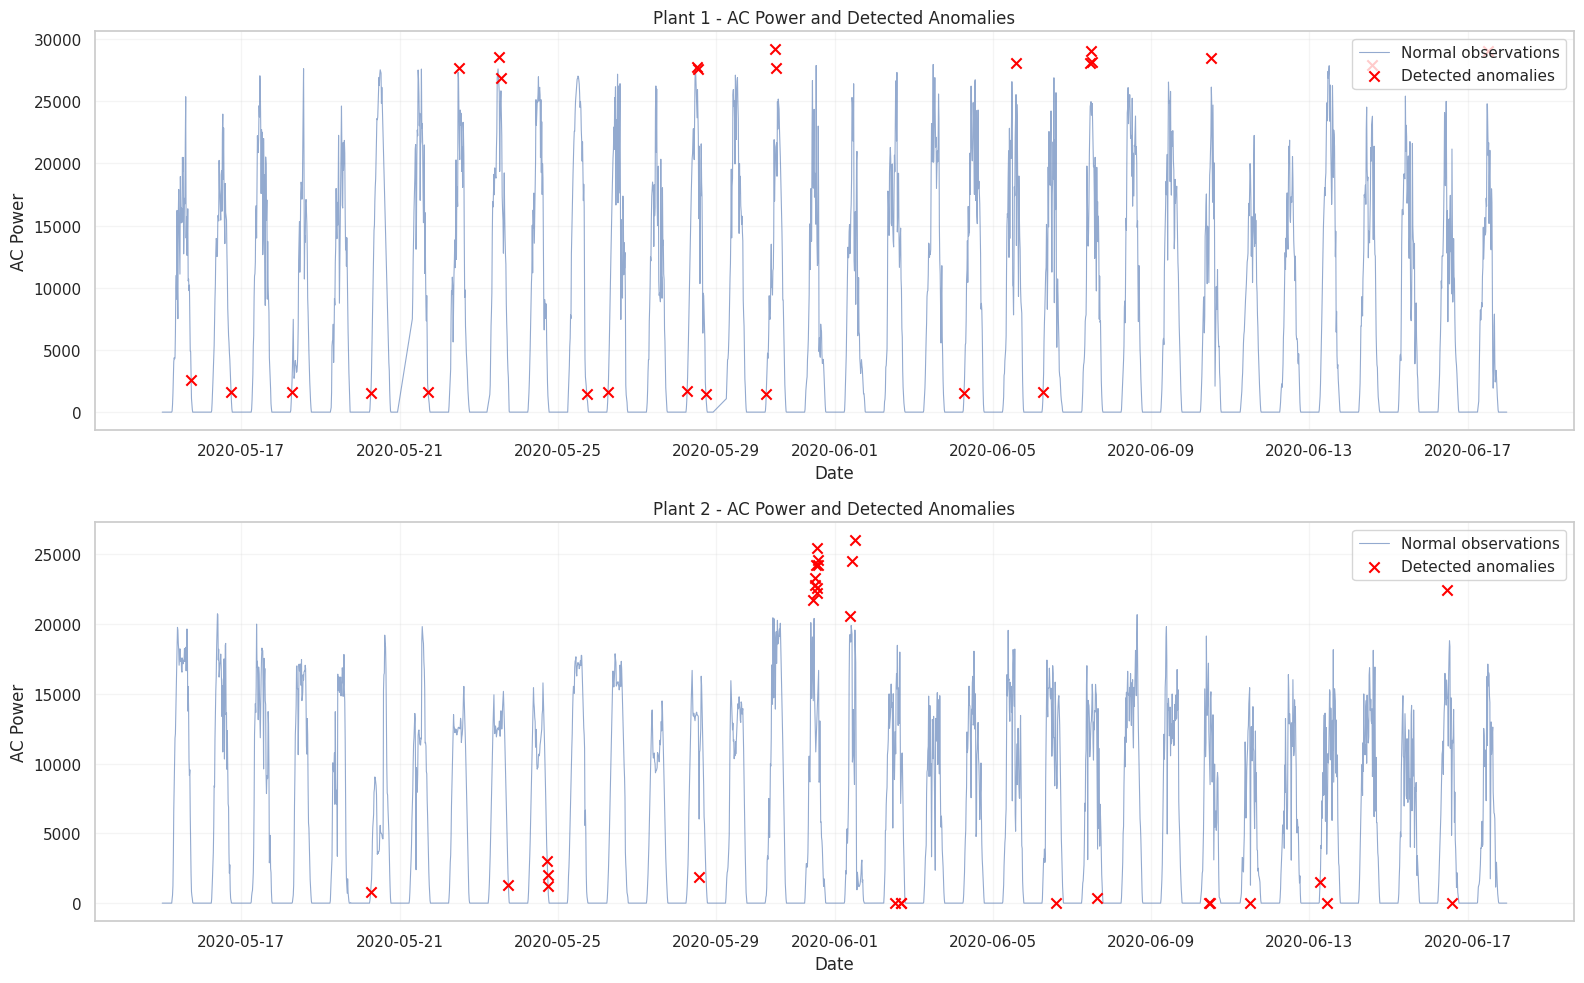

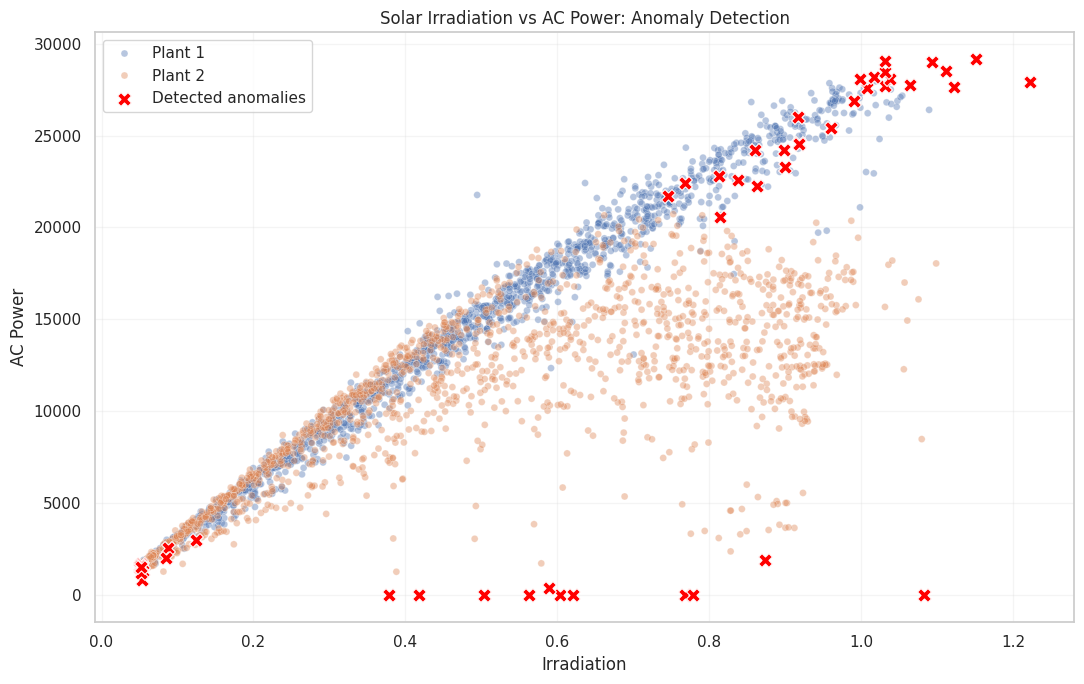

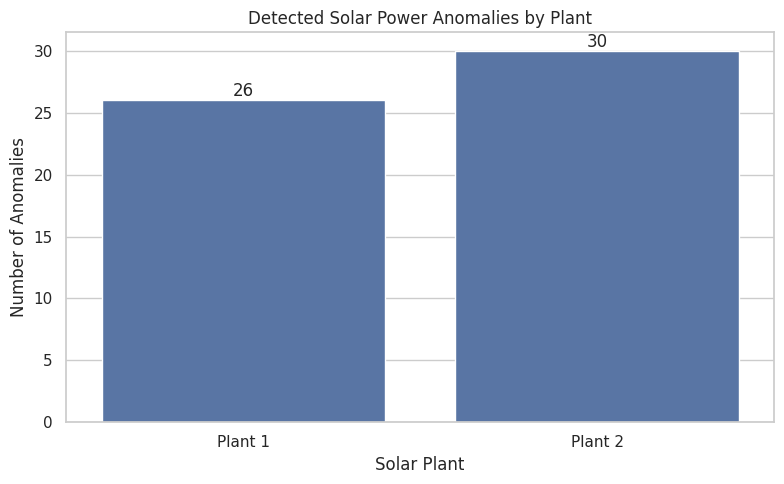

ANOMALY DETECTION SUMMARY


,PLANT,Anomaly Count
0,Plant 1,26
1,Plant 2,30



FIRST 15 DETECTED ANOMALIES


,DATE_TIME,PLANT,DC_POWER,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,ANOMALY_SCORE
4931,2020-06-02 12:30:00,Plant 2,0.000,0.000,1.083,31.940,62.564,-0.116
4743,2020-05-31 13:15:00,Plant 2,26057.343,25409.597,0.960,35.987,64.143,-0.105
4746,2020-05-31 14:00:00,Plant 2,25219.500,24595.294,0.919,36.761,62.752,-0.089
4745,2020-05-31 13:45:00,Plant 2,24824.874,24214.880,0.899,36.074,62.141,-0.074
746,2020-05-23 12:15:00,Plant 1,292463.339,28516.902,1.112,31.266,63.342,-0.072
1384,2020-05-30 12:00:00,Plant 1,298937.786,29150.212,1.151,27.093,57.691,-0.071
2148,2020-06-07 11:15:00,Plant 1,297395.286,28999.727,1.093,27.467,58.268,-0.065
4836,2020-06-01 12:30:00,Plant 2,26630.507,25979.760,0.917,32.714,49.317,-0.063
4827,2020-06-01 10:15:00,Plant 2,25125.952,24514.154,0.918,29.823,50.490,-0.056
5979,2020-06-13 10:45:00,Plant 2,0.000,0.000,0.503,28.721,45.338,-0.047


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Separate normal and anomalous observations
normal_data = anomaly_data[
    anomaly_data["ANOMALY"] == 0
].copy()

anomalous_data = anomaly_data[
    anomaly_data["ANOMALY"] == 1
].copy()

# ------------------------------------------------
# PLOT 1: AC POWER OVER TIME WITH ANOMALIES
# ------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

for ax, plant in zip(axes, ["Plant 1", "Plant 2"]):

    plant_normal = normal_data[
        normal_data["PLANT"] == plant
    ]

    plant_anomalies = anomalous_data[
        anomalous_data["PLANT"] == plant
    ]

    ax.plot(
        plant_normal["DATE_TIME"],
        plant_normal["AC_POWER"],
        label="Normal observations",
        alpha=0.6,
        linewidth=0.8
    )

    ax.scatter(
        plant_anomalies["DATE_TIME"],
        plant_anomalies["AC_POWER"],
        color="red",
        marker="x",
        s=55,
        label="Detected anomalies",
        zorder=3
    )

    ax.set_title(f"{plant} - AC Power and Detected Anomalies")
    ax.set_xlabel("Date")
    ax.set_ylabel("AC Power")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 2: IRRADIATION VS AC POWER
# ------------------------------------------------

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=normal_data[normal_data["IRRADIATION"] > 0.05],
    x="IRRADIATION",
    y="AC_POWER",
    hue="PLANT",
    alpha=0.4,
    s=25
)

sns.scatterplot(
    data=anomalous_data,
    x="IRRADIATION",
    y="AC_POWER",
    color="red",
    marker="X",
    s=100,
    label="Detected anomalies"
)

plt.title("Solar Irradiation vs AC Power: Anomaly Detection")
plt.xlabel("Irradiation")
plt.ylabel("AC Power")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 3: ANOMALY COUNT BY PLANT
# ------------------------------------------------

anomaly_counts = (
    anomalous_data.groupby("PLANT")
    .size()
    .reset_index(name="Anomaly Count")
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=anomaly_counts,
    x="PLANT",
    y="Anomaly Count"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Detected Solar Power Anomalies by Plant")
plt.xlabel("Solar Plant")
plt.ylabel("Number of Anomalies")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# DISPLAY ANOMALY SUMMARY
# ------------------------------------------------

print("ANOMALY DETECTION SUMMARY")
print("=" * 45)

display(
    anomaly_counts
)

print("\nFIRST 15 DETECTED ANOMALIES")

display(
    anomalous_data[
        [
            "DATE_TIME",
            "PLANT",
            "DC_POWER",
            "AC_POWER",
            "IRRADIATION",
            "AMBIENT_TEMPERATURE",
            "MODULE_TEMPERATURE",
            "ANOMALY_SCORE"
        ]
    ]
    .sort_values("ANOMALY_SCORE")
    .head(15)
    .round(3)
)

##Phase 6.3 — Engineering-based underperformance detection
Now we will add an independent engineering check.

The idea is straightforward:
- At similar irradiation levels, a solar plant should generally produce comparable power under similar operating conditions.
- We calculate the median expected AC power for each plant and irradiation range using training-period observations.
- We identify observations whose actual power is substantially below that expected level.

In [ ]:
import numpy as np
import pandas as pd

# 1. Prepare daylight data
engineering_data = solar_data[
    solar_data["IRRADIATION"] > 0.05
].copy()

# 2. Create irradiation intervals of 0.1
engineering_data["IRRADIATION_BIN"] = pd.cut(
    engineering_data["IRRADIATION"],
    bins=np.arange(0, 1.51, 0.1),
    include_lowest=True
)

# 3. Use training-period data to establish expected output
engineering_train = engineering_data[
    engineering_data["DATE_TIME"] < split_date
].copy()

# 4. Calculate median and median absolute deviation
def calculate_mad(values):
    median = np.median(values)
    return np.median(np.abs(values - median))

expected_power = (
    engineering_train
    .groupby(["PLANT", "IRRADIATION_BIN"], observed=True)
    .agg(
        EXPECTED_AC_POWER=("AC_POWER", "median"),
        POWER_MAD=("AC_POWER", calculate_mad),
        TRAIN_COUNT=("AC_POWER", "size")
    )
    .reset_index()
)

# 5. Attach expected power to all daylight observations
engineering_data = engineering_data.merge(
    expected_power,
    on=["PLANT", "IRRADIATION_BIN"],
    how="left"
)

# 6. Calculate underperformance
engineering_data["POWER_DIFFERENCE"] = (
    engineering_data["EXPECTED_AC_POWER"]
    - engineering_data["AC_POWER"]
)

# Robust lower threshold: median - 3 scaled MAD
engineering_data["LOWER_POWER_LIMIT"] = (
    engineering_data["EXPECTED_AC_POWER"]
    - 3 * 1.4826 * engineering_data["POWER_MAD"]
)

# Require sufficient historical observations
sufficient_history = engineering_data["TRAIN_COUNT"] >= 10

# Flag unusually low generation
engineering_data["POTENTIAL_UNDERPERFORMANCE"] = (
    (engineering_data["AC_POWER"] < engineering_data["LOWER_POWER_LIMIT"])
    & sufficient_history
).astype(int)

# 7. Display summary
print("ENGINEERING-BASED UNDERPERFORMANCE ANALYSIS")
print("=" * 55)

print("Total daylight observations:", len(engineering_data))

print(
    "Observations with sufficient historical comparison:",
    sufficient_history.sum()
)

print(
    "Potential underperformance observations:",
    engineering_data["POTENTIAL_UNDERPERFORMANCE"].sum()
)

print("\nRESULTS BY PLANT")

display(
    engineering_data.groupby("PLANT").agg(
        Observations=("AC_POWER", "size"),
        Potential_Underperformance=(
            "POTENTIAL_UNDERPERFORMANCE", "sum"
        )
    )
)

# 8. Show the most significant underperformance observations
print("\nTOP 15 POTENTIAL UNDERPERFORMANCE OBSERVATIONS")

display(
    engineering_data[
        engineering_data["POTENTIAL_UNDERPERFORMANCE"] == 1
    ][
        [
            "DATE_TIME",
            "PLANT",
            "AC_POWER",
            "EXPECTED_AC_POWER",
            "POWER_DIFFERENCE",
            "IRRADIATION",
            "MODULE_TEMPERATURE"
        ]
    ]
    .sort_values("POWER_DIFFERENCE", ascending=False)
    .head(15)
    .round(3)
)

ENGINEERING-BASED UNDERPERFORMANCE ANALYSIS
Total daylight observations: 3039
Observations with sufficient historical comparison: 3035
Potential underperformance observations: 37

RESULTS BY PLANT


,Observations,Potential_Underperformance
PLANT,,
Plant 1,1513,12
Plant 2,1526,25



TOP 15 POTENTIAL UNDERPERFORMANCE OBSERVATIONS


,DATE_TIME,PLANT,AC_POWER,EXPECTED_AC_POWER,POWER_DIFFERENCE,IRRADIATION,MODULE_TEMPERATURE
2332,2020-06-02 12:30:00,Plant 2,0.000,15888.722,15888.722,1.083,62.564
2525,2020-06-06 14:30:00,Plant 2,0.000,15132.181,15132.181,0.603,46.948
2742,2020-06-11 12:00:00,Plant 2,0.000,15132.181,15132.181,0.621,45.405
2698,2020-06-10 11:15:00,Plant 2,0.000,14794.500,14794.500,0.768,50.576
2699,2020-06-10 11:30:00,Plant 2,0.000,14794.500,14794.500,0.779,51.856
2985,2020-06-16 14:30:00,Plant 2,0.000,13872.738,13872.738,0.563,44.377
2829,2020-06-13 10:45:00,Plant 2,0.000,13872.738,13872.738,0.503,45.338
2574,2020-06-07 15:15:00,Plant 2,399.967,13872.738,13472.771,0.589,49.602
2348,2020-06-02 16:30:00,Plant 2,0.000,12813.509,12813.509,0.418,42.765
2121,2020-05-28 13:30:00,Plant 2,1899.740,14578.534,12678.794,0.873,57.171


##Phase 6.4 — Combine both detection methods
Now we will identify observations flagged by both methods. These are particularly important candidates because they satisfy two different anomaly criteria.

In [ ]:
# 1. Extract Isolation Forest anomaly flags
isolation_results = anomaly_data[
    ["PLANT", "DATE_TIME", "ANOMALY", "ANOMALY_SCORE"]
].copy()

# 2. Extract engineering-based detection results
engineering_results = engineering_data[
    [
        "PLANT",
        "DATE_TIME",
        "POTENTIAL_UNDERPERFORMANCE",
        "POWER_DIFFERENCE",
        "EXPECTED_AC_POWER"
    ]
].copy()

# 3. Combine both detection methods
combined_results = isolation_results.merge(
    engineering_results,
    on=["PLANT", "DATE_TIME"],
    how="inner"
)

# 4. Create combined classification
combined_results["DETECTION_CATEGORY"] = np.select(
    [
        (
            (combined_results["ANOMALY"] == 1) &
            (combined_results["POTENTIAL_UNDERPERFORMANCE"] == 1)
        ),
        (
            (combined_results["ANOMALY"] == 1) &
            (combined_results["POTENTIAL_UNDERPERFORMANCE"] == 0)
        ),
        (
            (combined_results["ANOMALY"] == 0) &
            (combined_results["POTENTIAL_UNDERPERFORMANCE"] == 1)
        )
    ],
    [
        "Both methods",
        "Isolation Forest only",
        "Engineering method only"
    ],
    default="Normal"
)

# 5. Summarize detection agreement
print("COMBINED FAULT-DETECTION SUMMARY")
print("=" * 50)

display(
    combined_results["DETECTION_CATEGORY"]
    .value_counts()
    .rename_axis("Detection Category")
    .reset_index(name="Observation Count")
)

# 6. Summary by plant
print("\nDETECTION RESULTS BY PLANT")

display(
    combined_results.pivot_table(
        index="PLANT",
        columns="DETECTION_CATEGORY",
        values="DATE_TIME",
        aggfunc="count",
        fill_value=0
    )
)

# 7. Display observations detected by both methods
both_methods = combined_results[
    combined_results["DETECTION_CATEGORY"] == "Both methods"
].sort_values("POWER_DIFFERENCE", ascending=False)

print("\nOBSERVATIONS FLAGGED BY BOTH METHODS")

display(
    both_methods[
        [
            "DATE_TIME",
            "PLANT",
            "ANOMALY_SCORE",
            "AC_POWER" if "AC_POWER" in combined_results.columns else "DATE_TIME",
            "EXPECTED_AC_POWER",
            "POWER_DIFFERENCE"
        ]
    ].head(20)
)

COMBINED FAULT-DETECTION SUMMARY


,Detection Category,Observation Count
0,Normal,2957
1,Isolation Forest only,45
2,Engineering method only,26
3,Both methods,11



DETECTION RESULTS BY PLANT


DETECTION_CATEGORY,Both methods,Engineering method only,Isolation Forest only,Normal
PLANT,,,,
Plant 1,0,12,26,1475
Plant 2,11,14,19,1482



OBSERVATIONS FLAGGED BY BOTH METHODS


,DATE_TIME,PLANT,ANOMALY_SCORE,DATE_TIME,EXPECTED_AC_POWER,POWER_DIFFERENCE
2332,2020-06-02 12:30:00,Plant 2,-0.116437,2020-06-02 12:30:00,15888.721667,15888.721667
2742,2020-06-11 12:00:00,Plant 2,-0.046501,2020-06-11 12:00:00,15132.180952,15132.180952
2525,2020-06-06 14:30:00,Plant 2,-0.040935,2020-06-06 14:30:00,15132.180952,15132.180952
2699,2020-06-10 11:30:00,Plant 2,-0.035890,2020-06-10 11:30:00,14794.500000,14794.500000
2698,2020-06-10 11:15:00,Plant 2,-0.033285,2020-06-10 11:15:00,14794.500000,14794.500000
2829,2020-06-13 10:45:00,Plant 2,-0.047326,2020-06-13 10:45:00,13872.737619,13872.737619
2985,2020-06-16 14:30:00,Plant 2,-0.040575,2020-06-16 14:30:00,13872.737619,13872.737619
2574,2020-06-07 15:15:00,Plant 2,-0.027503,2020-06-07 15:15:00,13872.737619,13472.770952
2348,2020-06-02 16:30:00,Plant 2,-0.033380,2020-06-02 16:30:00,12813.508810,12813.508810
2121,2020-05-28 13:30:00,Plant 2,-0.028857,2020-05-28 13:30:00,14578.533810,12678.793810


In [ ]:
both_methods = combined_results[
    combined_results["DETECTION_CATEGORY"] == "Both methods"
].merge(
    solar_data[["PLANT", "DATE_TIME", "AC_POWER", "IRRADIATION"]],
    on=["PLANT", "DATE_TIME"],
    how="left"
)

display(
    both_methods[
        [
            "DATE_TIME",
            "PLANT",
            "AC_POWER",
            "IRRADIATION",
            "EXPECTED_AC_POWER",
            "POWER_DIFFERENCE",
            "ANOMALY_SCORE"
        ]
    ].sort_values(
        "POWER_DIFFERENCE",
        ascending=False
    ).head(20).round(3)
)

,DATE_TIME,PLANT,AC_POWER,IRRADIATION,EXPECTED_AC_POWER,POWER_DIFFERENCE,ANOMALY_SCORE
1,2020-06-02 12:30:00,Plant 2,0.000,1.083,15888.722,15888.722,-0.116
8,2020-06-11 12:00:00,Plant 2,0.000,0.621,15132.181,15132.181,-0.047
4,2020-06-06 14:30:00,Plant 2,0.000,0.603,15132.181,15132.181,-0.041
7,2020-06-10 11:30:00,Plant 2,0.000,0.779,14794.500,14794.500,-0.036
6,2020-06-10 11:15:00,Plant 2,0.000,0.768,14794.500,14794.500,-0.033
9,2020-06-13 10:45:00,Plant 2,0.000,0.503,13872.738,13872.738,-0.047
10,2020-06-16 14:30:00,Plant 2,0.000,0.563,13872.738,13872.738,-0.041
5,2020-06-07 15:15:00,Plant 2,399.967,0.589,13872.738,13472.771,-0.028
3,2020-06-02 16:30:00,Plant 2,0.000,0.418,12813.509,12813.509,-0.033
0,2020-05-28 13:30:00,Plant 2,1899.740,0.873,14578.534,12678.794,-0.029


##Phase 6.5 — Visualize the strongest potential underperformance events

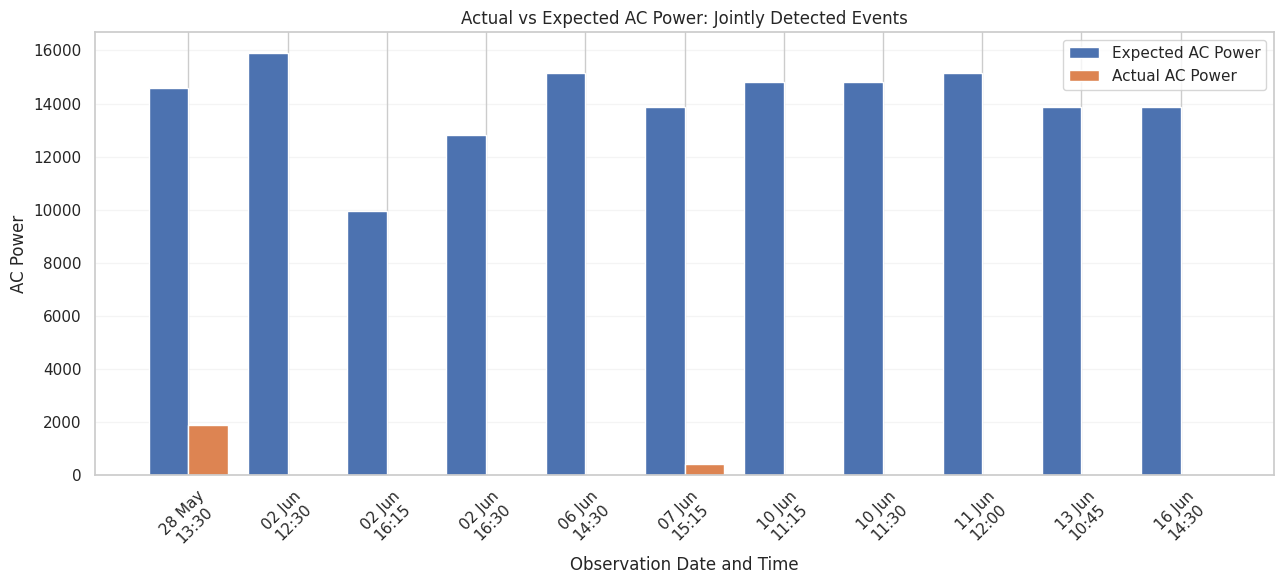

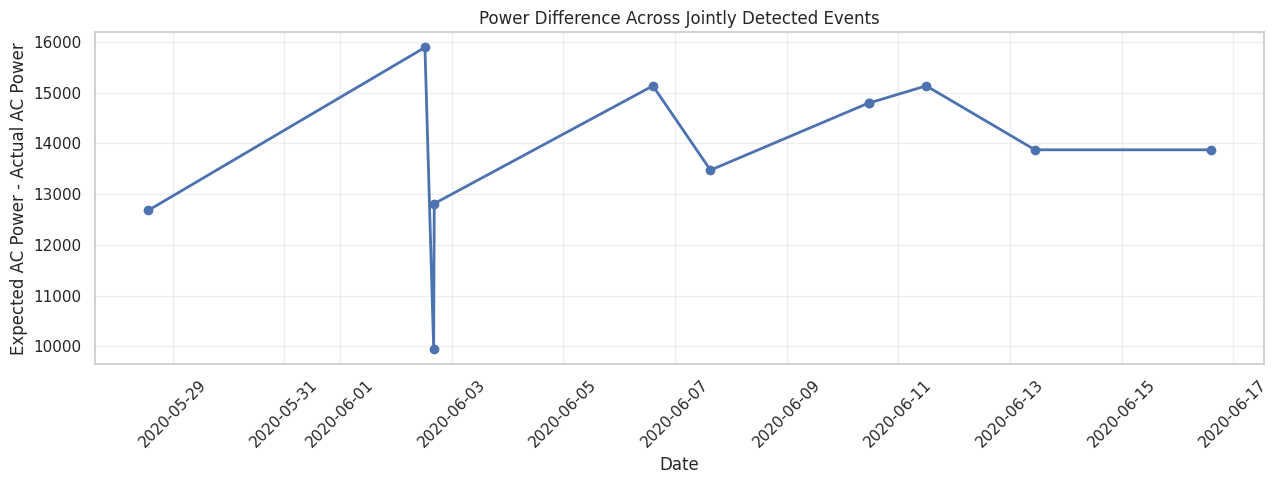

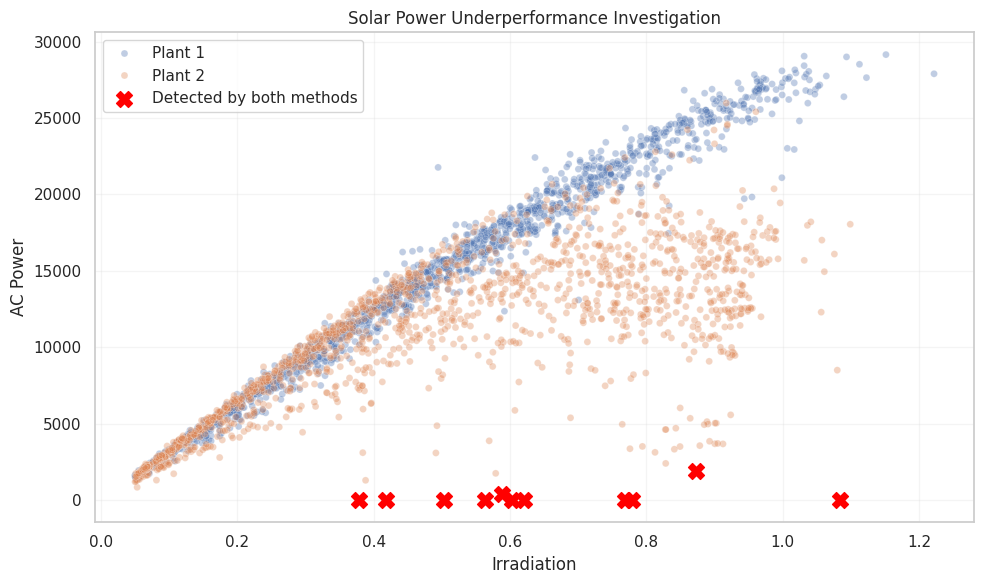

JOINT ANOMALY DETECTION SUMMARY
Jointly detected observations: 11
Average expected AC power: 14063.63
Average actual AC power: 209.06
Total estimated power difference: 152400.28


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare jointly detected observations
joint_events = both_methods.copy()

joint_events = joint_events.sort_values("DATE_TIME")

# ------------------------------------------------
# PLOT 1: ACTUAL VS EXPECTED AC POWER
# ------------------------------------------------

plt.figure(figsize=(13, 6))

x = np.arange(len(joint_events))

plt.bar(
    x - 0.2,
    joint_events["EXPECTED_AC_POWER"],
    width=0.4,
    label="Expected AC Power"
)

plt.bar(
    x + 0.2,
    joint_events["AC_POWER"],
    width=0.4,
    label="Actual AC Power"
)

plt.xticks(
    x,
    joint_events["DATE_TIME"].dt.strftime("%d %b\n%H:%M"),
    rotation=45
)

plt.title("Actual vs Expected AC Power: Jointly Detected Events")
plt.xlabel("Observation Date and Time")
plt.ylabel("AC Power")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 2: UNDERPERFORMANCE OVER TIME
# ------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(
    joint_events["DATE_TIME"],
    joint_events["POWER_DIFFERENCE"],
    marker="o",
    linewidth=2
)

plt.title("Power Difference Across Jointly Detected Events")
plt.xlabel("Date")
plt.ylabel("Expected AC Power - Actual AC Power")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# PLOT 3: IRRADIATION VS ACTUAL AC POWER
# ------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=engineering_data,
    x="IRRADIATION",
    y="AC_POWER",
    hue="PLANT",
    alpha=0.35,
    s=25
)

plt.scatter(
    joint_events["IRRADIATION"],
    joint_events["AC_POWER"],
    color="red",
    marker="X",
    s=130,
    label="Detected by both methods"
)

plt.title("Solar Power Underperformance Investigation")
plt.xlabel("Irradiation")
plt.ylabel("AC Power")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# FINAL JOINT DETECTION SUMMARY
# ------------------------------------------------

print("JOINT ANOMALY DETECTION SUMMARY")
print("=" * 45)

print("Jointly detected observations:", len(joint_events))

print(
    "Average expected AC power:",
    round(joint_events["EXPECTED_AC_POWER"].mean(), 2)
)

print(
    "Average actual AC power:",
    round(joint_events["AC_POWER"].mean(), 2)
)

print(
    "Total estimated power difference:",
    round(joint_events["POWER_DIFFERENCE"].sum(), 2)
)

##Phase 7 — Build the Solar Energy Monitoring Dashboard
We’ll now turn the forecasting and anomaly-detection work into an interactive Streamlit dashboard that can eventually be deployed and added to your GitHub portfolio.

The dashboard will include:
1. Overview: solar generation KPIs and plant comparisons.
2. Power Forecasting: actual versus predicted AC power.
3. Anomaly Detection: unusual observations identified by Isolation Forest.
4. Underperformance Monitoring: observations flagged by the engineering-based method.
5. Combined Alerts: cases flagged by both detection methods.

In [ ]:

# PHASE 7.1 — Check project readiness

required_objects = [
    "solar_data",
    "model_data",
    "combined_results",
    "both_methods",
    "linear_model",
    "rf_model",
    "xgb_model",
    "lstm_model",
]

print("PROJECT READINESS CHECK")
print("-" * 45)

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"✓ {name}: available — shape {obj.shape}")
        else:
            print(f"✓ {name}: available — {type(obj).__name__}")
    else:
        print(f"✗ {name}: not found")

print("-" * 45)

if "solar_data" in globals():
    print("Solar data columns:")
    print(solar_data.columns.tolist())

if "combined_results" in globals():
    print("\nDetection categories:")
    print(combined_results["DETECTION_CATEGORY"].value_counts())


PROJECT READINESS CHECK
---------------------------------------------
✓ solar_data: available — shape (6416, 11)
✓ model_data: available — shape (6399, 22)
✓ combined_results: available — shape (3039, 8)
✓ both_methods: available — shape (11, 10)
✓ linear_model: available — Pipeline
✓ rf_model: available — RandomForestRegressor
✓ xgb_model: available — XGBRegressor
✓ lstm_model: available — Sequential
---------------------------------------------
Solar data columns:
['DATE_TIME', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'PLANT']

Detection categories:
DETECTION_CATEGORY
Normal                     2957
Isolation Forest only        45
Engineering method only      26
Both methods                 11
Name: count, dtype: int64


##Step 7.2 — Identify the model artifacts we need to export

In [ ]:

# PHASE 7.2 — Inspect model and preprocessing artifacts

keywords = [
    "scaler", "model", "feature", "expected",
    "power", "metric", "prediction", "result"
]

print("AVAILABLE PROJECT ARTIFACTS")
print("=" * 55)

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in keywords):
        if not name.startswith("_"):
            if hasattr(obj, "shape"):
                print(f"{name}: {type(obj).__name__}, shape={obj.shape}")
            elif isinstance(obj, dict):
                print(f"{name}: dictionary, keys={list(obj.keys())}")
            elif isinstance(obj, (list, tuple)):
                print(f"{name}: {type(obj).__name__}, length={len(obj)}")
            else:
                print(f"{name}: {type(obj).__name__}")

print("\nFORECASTING FEATURES")
if "features" in globals():
    print(features)

print("\nISOLATION FOREST PLANTS")
if "isolation_models" in globals():
    print(list(isolation_models.keys()))


AVAILABLE PROJECT ARTIFACTS
quality_results: list, length=4
model_data: DataFrame, shape=(6399, 22)
features: list, length=10
StandardScaler: type
linear_model: Pipeline
rf_model: RandomForestRegressor
xgb_model: XGBRegressor
predictions: ndarray, shape=(1526,)
results: DataFrame, shape=(3, 4)
metrics: list, length=3
metric: str
MinMaxScaler: type
X_scaler: StandardScaler
y_scaler: MinMaxScaler
lstm_model: Sequential
common_results: DataFrame, shape=(1278, 7)
lstm_results: DataFrame, shape=(1278, 3)
model_names: list, length=4
fair_results: DataFrame, shape=(4, 4)
anomaly_features: list, length=5
isolation_models: dictionary, keys=['Plant 1', 'Plant 2']
iso_model: IsolationForest
expected_power: DataFrame, shape=(23, 5)
isolation_results: DataFrame, shape=(6416, 4)
engineering_results: DataFrame, shape=(3039, 5)
combined_results: DataFrame, shape=(3039, 8)

FORECASTING FEATURES
['DC_POWER', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR_SIN', 'HOUR_COS', 

##Step 7.3 — Inspect the result tables before exporting

In [ ]:
# PHASE 7.3 — Inspect tables for dashboard integration

tables_to_check = {
    "solar_data": solar_data,
    "common_results": common_results,
    "lstm_results": lstm_results,
    "fair_results": fair_results,
    "combined_results": combined_results,
    "expected_power": expected_power,
}

for name, df in tables_to_check.items():
    print("\n" + "=" * 65)
    print(f"{name.upper()}")
    print("Columns:", df.columns.tolist())
    print("Shape:", df.shape)
    display(df.head(3))


SOLAR_DATA
Columns: ['DATE_TIME', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'PLANT']
Shape: (6416, 11)


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT
0,2020-05-15 00:00:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,Plant 1
1,2020-05-15 00:15:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,Plant 1
2,2020-05-15 00:30:00,0.0,0.0,0.0,143581676.0,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,Plant 1



COMMON_RESULTS
Columns: ['PLANT', 'DATE_TIME', 'TARGET_AC_POWER', 'Linear Regression', 'Random Forest', 'XGBoost', 'LSTM']
Shape: (1278, 7)


,PLANT,DATE_TIME,TARGET_AC_POWER,Linear Regression,Random Forest,XGBoost,LSTM
0,Plant 1,2020-06-11 07:15:00,3155.857143,4105.838528,3596.106130,3680.811035,2780.885498
1,Plant 1,2020-06-11 07:30:00,4351.608929,4669.513192,4403.974884,4244.589844,4119.902344
2,Plant 1,2020-06-11 07:45:00,5576.767857,5728.554371,5343.660541,5947.745117,5738.376465



LSTM_RESULTS
Columns: ['PLANT', 'DATE_TIME', 'LSTM']
Shape: (1278, 3)


,PLANT,DATE_TIME,LSTM
0,Plant 1,2020-06-11 07:15:00,2780.885498
1,Plant 1,2020-06-11 07:30:00,4119.902344
2,Plant 1,2020-06-11 07:45:00,5738.376465


... (2 outputs left out)


COMBINED_RESULTS
Columns: ['PLANT', 'DATE_TIME', 'ANOMALY', 'ANOMALY_SCORE', 'POTENTIAL_UNDERPERFORMANCE', 'POWER_DIFFERENCE', 'EXPECTED_AC_POWER', 'DETECTION_CATEGORY']
Shape: (3039, 8)


,PLANT,DATE_TIME,ANOMALY,ANOMALY_SCORE,POTENTIAL_UNDERPERFORMANCE,POWER_DIFFERENCE,EXPECTED_AC_POWER,DETECTION_CATEGORY
0,Plant 1,2020-05-15 06:45:00,0,0.065202,0,-601.098214,2189.350000,Normal
1,Plant 1,2020-05-15 07:00:00,0,0.091449,0,280.777143,4333.439286,Normal
2,Plant 1,2020-05-15 07:15:00,0,0.099369,0,-35.283333,4333.439286,Normal



EXPECTED_POWER
Columns: ['PLANT', 'IRRADIATION_BIN', 'EXPECTED_AC_POWER', 'POWER_MAD', 'TRAIN_COUNT']
Shape: (23, 5)


,PLANT,IRRADIATION_BIN,EXPECTED_AC_POWER,POWER_MAD,TRAIN_COUNT
0,Plant 1,"(-0.001, 0.1]",2189.350000,404.907143,91
1,Plant 1,"(0.1, 0.2]",4333.439286,600.938393,142
2,Plant 1,"(0.2, 0.3]",7457.653572,803.317857,121


In [ ]:

# PHASE 7.4 — Export dashboard data and trained models

import os
import json
import joblib
import pandas as pd

from pathlib import Path

# Create project directories
project_dir = Path("/content/solar_monitoring_dashboard")
data_dir = project_dir / "data"
models_dir = project_dir / "models"

data_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Export datasets
solar_data.to_csv(data_dir / "solar_data.csv", index=False)
common_results.to_csv(data_dir / "forecast_results.csv", index=False)
fair_results.to_csv(data_dir / "model_metrics.csv", index=False)
combined_results.to_csv(data_dir / "detection_results.csv", index=False)
expected_power.to_csv(data_dir / "expected_power.csv", index=False)

# 2. Export classical forecasting models
joblib.dump(linear_model, models_dir / "linear_regression.joblib")
joblib.dump(rf_model, models_dir / "random_forest.joblib")
joblib.dump(xgb_model, models_dir / "xgboost.joblib")

# 3. Export LSTM model and scalers
lstm_model.save(models_dir / "lstm_model.keras")
joblib.dump(X_scaler, models_dir / "lstm_X_scaler.joblib")
joblib.dump(y_scaler, models_dir / "lstm_y_scaler.joblib")

# 4. Export Isolation Forest models
joblib.dump(isolation_models, models_dir / "isolation_forest_models.joblib")

# 5. Export feature configuration
metadata = {
    "forecasting_features": features,
    "anomaly_features": anomaly_features,
    "forecast_target": target,
    "sequence_length": 4,
    "forecast_horizon_minutes": 15,
    "plants": ["Plant 1", "Plant 2"]
}

with open(project_dir / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

# 6. Verify exported files
print("PROJECT EXPORT COMPLETED")
print("=" * 55)

for folder in [data_dir, models_dir]:
    print(f"\n{folder.name.upper()}:")
    for file in sorted(folder.iterdir()):
        print(f"✓ {file.name} — {file.stat().st_size / 1024:.2f} KB")

print("\nMetadata:")
print("✓ metadata.json")

print("\nProject directory:", project_dir)


PROJECT EXPORT COMPLETED

DATA:
✓ detection_results.csv — 280.37 KB
✓ expected_power.csv — 1.39 KB
✓ forecast_results.csv — 111.03 KB
✓ model_metrics.csv — 0.28 KB
✓ solar_data.csv — 906.88 KB

MODELS:
✓ isolation_forest_models.joblib — 5841.82 KB
✓ linear_regression.joblib — 1.77 KB
✓ lstm_X_scaler.joblib — 1.21 KB
✓ lstm_model.keras — 417.80 KB
✓ lstm_y_scaler.joblib — 0.97 KB
✓ random_forest.joblib — 21343.25 KB
✓ xgboost.joblib — 1900.82 KB

Metadata:
✓ metadata.json

Project directory: /content/solar_monitoring_dashboard


In [ ]:
# PHASE 7.5 — Create downloadable project ZIP

import shutil
from google.colab import files
from pathlib import Path

project_dir = Path("/content/solar_monitoring_dashboard")

zip_path = shutil.make_archive(
    "/content/solar_monitoring_dashboard",
    "zip",
    root_dir="/content",
    base_dir="solar_monitoring_dashboard"
)

print("ZIP FILE CREATED")
print("File:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / (1024 * 1024), 2), "MB")

# Download to your computer
files.download(zip_path)

ZIP FILE CREATED
File: /content/solar_monitoring_dashboard.zip
Size: 9.68 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile /content/solar_monitoring_dashboard/app.py

import streamlit as st
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="AI Solar Monitoring Dashboard",
    page_icon="☀️",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"

# --------------------------------------------------
# 2. LOAD PROJECT DATA
# --------------------------------------------------

@st.cache_data
def load_data():

    solar = pd.read_csv(DATA_DIR / "solar_data.csv")
    forecasts = pd.read_csv(DATA_DIR / "forecast_results.csv")
    metrics = pd.read_csv(DATA_DIR / "model_metrics.csv")
    detections = pd.read_csv(DATA_DIR / "detection_results.csv")

    for df in [solar, forecasts, detections]:
        df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

    # Add actual solar measurements to detection records
    detections = detections.merge(
        solar[
            [
                "PLANT",
                "DATE_TIME",
                "AC_POWER",
                "DC_POWER",
                "IRRADIATION",
                "MODULE_TEMPERATURE"
            ]
        ],
        on=["PLANT", "DATE_TIME"],
        how="left"
    )

    return solar, forecasts, metrics, detections


solar, forecasts, metrics, detections = load_data()

# --------------------------------------------------
# 3. DASHBOARD HEADER
# --------------------------------------------------

st.title("☀️ AI-Powered Solar Energy Monitoring")
st.markdown(
    """
    **Solar Power Forecasting | Anomaly Detection | "
    "Potential Underperformance Monitoring**

    An intelligent monitoring dashboard developed using "
    "Machine Learning and Deep Learning.
    """
)

st.caption(
    "Dataset: Solar Power Generation Data | "
    "Historical observations: May–June 2020"
)

# --------------------------------------------------
# 4. SIDEBAR FILTERS
# --------------------------------------------------

st.sidebar.header("Dashboard Filters")

plants = ["All Plants"] + sorted(solar["PLANT"].unique().tolist())

selected_plant = st.sidebar.selectbox(
    "Select Solar Plant",
    plants
)

minimum_date = solar["DATE_TIME"].min().date()
maximum_date = solar["DATE_TIME"].max().date()

selected_dates = st.sidebar.date_input(
    "Select Date Range",
    value=(minimum_date, maximum_date),
    min_value=minimum_date,
    max_value=maximum_date
)

if len(selected_dates) == 2:

    start_date, end_date = selected_dates

    start_time = pd.Timestamp(start_date)
    end_time = pd.Timestamp(end_date) + pd.Timedelta(days=1)

    solar_filtered = solar[
        (solar["DATE_TIME"] >= start_time) &
        (solar["DATE_TIME"] < end_time)
    ].copy()

    forecast_filtered = forecasts[
        (forecasts["DATE_TIME"] >= start_time) &
        (forecasts["DATE_TIME"] < end_time)
    ].copy()

    detection_filtered = detections[
        (detections["DATE_TIME"] >= start_time) &
        (detections["DATE_TIME"] < end_time)
    ].copy()

else:
    st.warning("Please select both a start date and an end date.")
    st.stop()

if selected_plant != "All Plants":

    solar_filtered = solar_filtered[
        solar_filtered["PLANT"] == selected_plant
    ]

    forecast_filtered = forecast_filtered[
        forecast_filtered["PLANT"] == selected_plant
    ]

    detection_filtered = detection_filtered[
        detection_filtered["PLANT"] == selected_plant
    ]

if solar_filtered.empty:
    st.warning("No observations found for the selected filters.")
    st.stop()

# --------------------------------------------------
# 5. OVERVIEW METRICS
# --------------------------------------------------

st.header("1. Solar Plant Overview")

total_observations = len(solar_filtered)

average_ac_power = solar_filtered["AC_POWER"].mean()

total_dc_power = solar_filtered["DC_POWER"].sum()

total_anomalies = (
    detection_filtered["ANOMALY"].sum()
)

total_underperformance = (
    detection_filtered["POTENTIAL_UNDERPERFORMANCE"].sum()
)

both_methods = (
    detection_filtered["DETECTION_CATEGORY"]
    == "Both methods"
).sum()

col1, col2, col3, col4, col5 = st.columns(5)

col1.metric("Observations", f"{total_observations:,}")
col2.metric("Average AC Power", f"{average_ac_power:,.2f}")
col3.metric("Total DC Power Readings", f"{total_dc_power:,.2f}")
col4.metric("Isolation Forest Alerts", f"{int(total_anomalies):,}")
col5.metric("Both Methods", f"{int(both_methods):,}")

st.caption(
    "Power values retain the units reported by the source dataset. "
    "Total DC power readings are a sum of interval observations, "
    "not an energy measurement."
)

# --------------------------------------------------
# 6. SOLAR POWER GENERATION TREND
# --------------------------------------------------

st.subheader("Solar Power Generation Trend")

daily_generation = (
    solar_filtered
    .assign(DATE=solar_filtered["DATE_TIME"].dt.date)
    .groupby(["DATE", "PLANT"], as_index=False)
    .agg(
        AC_POWER=("AC_POWER", "mean"),
        DC_POWER=("DC_POWER", "mean")
    )
)

fig_generation = px.line(
    daily_generation,
    x="DATE",
    y="AC_POWER",
    color="PLANT",
    markers=True,
    title="Average AC Power by Day",
    labels={
        "DATE": "Date",
        "AC_POWER": "Average AC Power",
        "PLANT": "Solar Plant"
    }
)

st.plotly_chart(fig_generation, use_container_width=True)

# --------------------------------------------------
# 7. PLANT COMPARISON
# --------------------------------------------------

st.subheader("Solar Plant Comparison")

plant_comparison = (
    solar_filtered
    .groupby("PLANT", as_index=False)
    .agg(
        Average_AC_Power=("AC_POWER", "mean"),
        Average_Irradiation=("IRRADIATION", "mean"),
        Average_Module_Temperature=("MODULE_TEMPERATURE", "mean")
    )
)

col1, col2 = st.columns(2)

with col1:
    fig_plant = px.bar(
        plant_comparison,
        x="PLANT",
        y="Average_AC_Power",
        color="PLANT",
        title="Average AC Power by Plant"
    )
    st.plotly_chart(fig_plant, use_container_width=True)

with col2:
    fig_irradiation = px.bar(
        plant_comparison,
        x="PLANT",
        y="Average_Irradiation",
        color="PLANT",
        title="Average Irradiation by Plant"
    )
    st.plotly_chart(fig_irradiation, use_container_width=True)

# --------------------------------------------------
# 8. FORECASTING PERFORMANCE
# --------------------------------------------------

st.header("2. AI Power Forecasting")

st.markdown(
    "Compare actual next-interval AC power with the "
    "predictions generated by four trained models."
)

if not forecast_filtered.empty:

    model_options = [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "LSTM"
    ]

    selected_model = st.selectbox(
        "Choose Forecasting Model",
        model_options
    )

    forecast_plot = forecast_filtered.sort_values("DATE_TIME")

    fig_forecast = go.Figure()

    fig_forecast.add_trace(
        go.Scatter(
            x=forecast_plot["DATE_TIME"],
            y=forecast_plot["TARGET_AC_POWER"],
            mode="lines",
            name="Actual AC Power"
        )
    )

    fig_forecast.add_trace(
        go.Scatter(
            x=forecast_plot["DATE_TIME"],
            y=forecast_plot[selected_model],
            mode="lines",
            name=f"{selected_model} Prediction"
        )
    )

    fig_forecast.update_layout(
        title=f"Actual vs Predicted AC Power — {selected_model}",
        xaxis_title="Timestamp",
        yaxis_title="AC Power",
        hovermode="x unified"
    )

    st.plotly_chart(fig_forecast, use_container_width=True)

else:
    st.info("No forecasting records available for these filters.")

st.subheader("Forecasting Model Evaluation")

st.dataframe(
    metrics.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "R2": "{:.4f}"
    }),
    use_container_width=True,
    hide_index=True
)

# --------------------------------------------------
# 9. ANOMALY DETECTION
# --------------------------------------------------

st.header("3. AI Anomaly Detection")

st.markdown(
    "Isolation Forest identifies unusual operating observations "
    "during daylight conditions. These observations require "
    "engineering investigation before being classified as faults."
)

category_counts = (
    detection_filtered["DETECTION_CATEGORY"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

col1, col2 = st.columns(2)

with col1:

    fig_anomalies = px.pie(
        category_counts,
        names="Category",
        values="Count",
        title="Detection Category Distribution",
        hole=0.4
    )

    st.plotly_chart(fig_anomalies, use_container_width=True)

with col2:

    fig_scatter = px.scatter(
        detection_filtered,
        x="IRRADIATION",
        y="AC_POWER",
        color="DETECTION_CATEGORY",
        hover_data=["PLANT", "DATE_TIME"],
        title="AC Power vs Irradiation"
    )

    st.plotly_chart(fig_scatter, use_container_width=True)

# --------------------------------------------------
# 10. POTENTIAL UNDERPERFORMANCE ALERTS
# --------------------------------------------------

st.header("4. Potential Underperformance Alerts")

st.markdown(
    "These records were flagged by the engineering-based "
    "statistical method or by both detection methods."
)

alert_data = detection_filtered[
    detection_filtered["POTENTIAL_UNDERPERFORMANCE"] == 1
].copy()

if not alert_data.empty:

    alert_columns = [
        "PLANT",
        "DATE_TIME",
        "AC_POWER",
        "EXPECTED_AC_POWER",
        "POWER_DIFFERENCE",
        "IRRADIATION",
        "DETECTION_CATEGORY"
    ]

    st.dataframe(
        alert_data[alert_columns].sort_values(
            "POWER_DIFFERENCE",
            ascending=True
        ),
        use_container_width=True,
        hide_index=True
    )

else:
    st.success("No potential underperformance records in this selection.")

# --------------------------------------------------
# 11. PRIORITY ALERTS — BOTH METHODS
# --------------------------------------------------

st.subheader("Priority Investigation Records")

priority_alerts = detection_filtered[
    detection_filtered["DETECTION_CATEGORY"] == "Both methods"
].copy()

if not priority_alerts.empty:

    st.warning(
        f"{len(priority_alerts)} observations were flagged by both "
        "detection methods in the selected period."
    )

    st.dataframe(
        priority_alerts[
            [
                "PLANT",
                "DATE_TIME",
                "AC_POWER",
                "EXPECTED_AC_POWER",
                "IRRADIATION",
                "ANOMALY_SCORE"
            ]
        ],
        use_container_width=True,
        hide_index=True
    )

else:
    st.info("No joint detection records in this selection.")

# --------------------------------------------------
# 12. DOWNLOAD FILTERED RESULTS
# --------------------------------------------------

st.header("5. Export Monitoring Results")

csv_data = detection_filtered.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Detection Results (CSV)",
    data=csv_data,
    file_name="solar_detection_results.csv",
    mime="text/csv"
)

st.caption(
    "Developed as an AI-powered solar energy monitoring "
    "and decision-support prototype. Historical data only; "
    "alerts are not confirmed equipment faults."
)

st.divider()

st.markdown(
    "**AI-Powered Solar Energy Forecasting and Fault Detection**  \n"
    "Machine Learning | Deep Learning | Electrical Engineering"
)


Writing /content/solar_monitoring_dashboard/app.py


In [ ]:

# FINAL PROJECT SETUP — REQUIREMENTS, README, VALIDATION AND ZIP

from pathlib import Path
import shutil
import zipfile

project_dir = Path("/content/solar_monitoring_dashboard")

# --------------------------------------------------
# 1. CREATE REQUIREMENTS.TXT
# --------------------------------------------------

requirements = """
streamlit>=1.40,<2.0
pandas>=2.2,<3.0
numpy>=1.26,<3.0
plotly>=5.24,<7.0
"""

(project_dir / "requirements.txt").write_text(
    requirements.strip() + "\n"
)

# --------------------------------------------------
# 2. CREATE README.MD
# --------------------------------------------------

readme = r"""
# AI-Powered Solar Energy Forecasting and Fault Detection

An intelligent solar energy monitoring and decision-support
prototype combining Electrical Engineering, Machine Learning,
Deep Learning, and statistical anomaly detection.

## Project Overview

This project analyzes solar power generation data from two plants.
It combines four forecasting models with two complementary
anomaly-detection approaches.

### Main Features

- Solar generation monitoring and plant comparison
- 15-minute-ahead AC power forecasting
- Linear Regression, Random Forest, XGBoost, and LSTM comparison
- Isolation Forest anomaly detection
- Engineering-based potential underperformance detection
- Combined alerts for observations flagged by both methods
- Interactive Streamlit dashboard
- CSV export of filtered monitoring results

## Model Evaluation

The models were evaluated on 1,278 common test observations.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 1287.25 | 2128.82 | 0.9047 |
| Random Forest | 1090.71 | 2151.62 | 0.9026 |
| XGBoost | 1107.55 | 2213.34 | 0.8969 |
| LSTM | 1376.86 | 2474.36 | 0.8712 |

Random Forest achieved the lowest MAE, while Linear Regression
achieved the best RMSE and R².

## Anomaly Detection

The project uses:

1. Isolation Forest to identify unusual daylight observations.
2. An engineering-based statistical method to identify
   potential underperformance relative to historical power output.
3. Combined detection to prioritize observations flagged by
   both methods.

An alert is an indication for investigation, not proof of
an equipment fault.

## Dataset

Dataset: Solar Power Generation Data

Source:
https://www.kaggle.com/datasets/anikannal/solar-power-generation-data

The dataset contains generation and weather observations
from two solar plants.

Check the original dataset's license and terms before
redistributing its data files.

## Project Structure

```text
solar_monitoring_dashboard/
│
├── app.py
├── requirements.txt
├── README.md
├── metadata.json
│
├── data/
│   ├── solar_data.csv
│   ├── forecast_results.csv
│   ├── model_metrics.csv
│   ├── detection_results.csv
│   └── expected_power.csv
│
└── models/
    ├── linear_regression.joblib
    ├── random_forest.joblib
    ├── xgboost.joblib
    ├── lstm_model.keras
    ├── lstm_X_scaler.joblib
    ├── lstm_y_scaler.joblib
    └── isolation_forest_models.joblib
```

## Installation

Python 3.11 is a recommended starting point.

Clone the repository:

```bash
git clone https://github.com/YOUR_USERNAME/solar-monitoring-dashboard.git
cd solar-monitoring-dashboard
```

Create a virtual environment:

```bash
python -m venv venv
```

Activate it on Windows:

```bash
venv\Scripts\activate
```

Install dependencies:

```bash
pip install -r requirements.txt
```

## Run the Dashboard

```bash
streamlit run app.py
```

The dashboard will normally open at:

http://localhost:8501

## Deployment

The application can be deployed through Streamlit Community
Cloud by connecting the GitHub repository and selecting `app.py`
as the application entry point.

## Important Limitations

- The dashboard uses historical observations, not live plant telemetry.
- Forecast charts display previously evaluated model predictions.
- The dashboard does not retrain models during operation.
- Anomaly alerts require engineering inspection before any
  physical fault can be confirmed.
- Power values retain the units reported in the source dataset.

## Technologies

- Python
- Pandas and NumPy
- Scikit-learn
- XGBoost
- TensorFlow / Keras
- Plotly
- Streamlit
- Google Colab
- GitHub

## Author

Electrical Engineering | Artificial Intelligence |
Robotics | Renewable Energy

Developed as an applied AI and electrical engineering
portfolio project.
"""

(project_dir / "README.md").write_text(readme.strip() + "\n")

# --------------------------------------------------
# 3. CREATE .GITIGNORE
# --------------------------------------------------

gitignore = """
__pycache__/
*.py[cod]
venv/
.env
.DS_Store
.streamlit/secrets.toml
.ipynb_checkpoints/
"""

(project_dir / ".gitignore").write_text(
    gitignore.strip() + "\n"
)

# --------------------------------------------------
# 4. VALIDATE PROJECT FILES
# --------------------------------------------------

required_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    ".gitignore",
    "metadata.json",
    "data/solar_data.csv",
    "data/forecast_results.csv",
    "data/model_metrics.csv",
    "data/detection_results.csv",
    "data/expected_power.csv",
    "models/linear_regression.joblib",
    "models/random_forest.joblib",
    "models/xgboost.joblib",
    "models/lstm_model.keras",
    "models/lstm_X_scaler.joblib",
    "models/lstm_y_scaler.joblib",
    "models/isolation_forest_models.joblib",
]

missing_files = [
    file for file in required_files
    if not (project_dir / file).is_file()
]

print("=" * 60)
print("PROJECT VALIDATION")
print("=" * 60)

if missing_files:
    print("Missing files:")
    for file in missing_files:
        print("✗", file)
    raise FileNotFoundError("Project validation failed.")

print(f"SUCCESS: All {len(required_files)} required files exist.")

# --------------------------------------------------
# 5. CREATE FINAL ZIP
# --------------------------------------------------

zip_path = shutil.make_archive(
    "/content/AI_Powered_Solar_Monitoring_Project",
    "zip",
    root_dir="/content",
    base_dir="solar_monitoring_dashboard"
)

print("\nPROJECT PACKAGE")
print("=" * 60)
print("ZIP:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / (1024 * 1024), 2), "MB")

# --------------------------------------------------
# 6. VERIFY ZIP CONTENTS
# --------------------------------------------------

with zipfile.ZipFile(zip_path, "r") as archive:
    zip_contents = archive.namelist()

print("Files packaged:", len(zip_contents))
print("\nPROJECT COMPLETED SUCCESSFULLY!")

# --------------------------------------------------
# 7. DOWNLOAD FINAL PROJECT
# --------------------------------------------------

from google.colab import files
files.download(zip_path)


PROJECT VALIDATION
SUCCESS: All 17 required files exist.

PROJECT PACKAGE
ZIP: /content/AI_Powered_Solar_Monitoring_Project.zip
Size: 9.68 MB
Files packaged: 20

PROJECT COMPLETED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>